# Machine Learning: Geospatial Machine Learning

> **Who is this for:** you know the basics of supervised learning and now meet data that has a **location**: house prices, delivery times, sensor readings, crime reports, store sales. You may also be a BS/MS student taking a spatial data science or GIS elective, or preparing for interviews at mapping, mobility, delivery, insurance or climate companies.
>
> **What you will learn:**
> - Latitude/longitude, **coordinate reference systems (CRS)** and map projections, and why Euclidean distance on raw degrees is wrong
> - The **haversine** great-circle distance from scratch, checked against scikit-learn
> - **Spatial indexing:** a grid index and a **geohash** encoder/decoder from scratch, and a **Ball tree** with the haversine metric
> - **Spatial features:** distance to points of interest (POIs), counts within a radius, neighbourhood aggregates and kernel density
> - **Spatial autocorrelation** with **Moran's I** from scratch, and why random cross-validation leaks, fixed with **spatial block cross-validation**
> - **Spatial interpolation:** inverse distance weighting (IDW) and **Gaussian-process kriging**, with a semivariogram
> - **Hotspot detection** with DBSCAN and the haversine metric
> - A **routing and ETA** mini-model on a synthetic road graph: a learned speed model plus shortest paths
> - Point-in-polygon and a spatial join from scratch, with optional geopandas/shapely equivalents
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [linear regression](../01_supervised/01_linear_regression.ipynb) and [KNN](../01_supervised/07_knn.ipynb); [model evaluation and cross-validation](../06_model_evaluation/01_model_evaluation.ipynb); [graphs](../../00_AI_Fundamentals/dsa/07_graphs.ipynb). Helpful: [Gaussian processes from scratch](../../14_Mathematics/07_bayesian_ml.ipynb) (section 4) and [KD-trees](../../00_AI_Fundamentals/advanced_algorithms/08_advanced_data_structures.ipynb) (section 4).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. All data is synthetic and generated in the notebook. The whole notebook runs in about a minute. geopandas/shapely are optional; the lesson works without them.
>
> **Optional track:** this notebook is part of the university-level fundamentals track (domain electives); recommended for BS/MS AI students and interview prep. It follows the spatial chapters of Rey, Arribas-Bel & Wolf, *Geographic Data Science with Python* (2023) and Cressie & Wikle, *Statistics for Spatio-Temporal Data* (2011).

## Explained simply

Most data you will meet has a hidden column: **where** it happened. A flat near a metro station costs more than the same flat 5 km away; a pizza takes longer to reach a house across the river. Geospatial machine learning is ordinary machine learning plus a few special tricks for handling "where".

The first trick is measuring distance properly. The Earth is round, so the numbers on a map (latitude and longitude) are **angles**, not kilometres. Think of an orange: lines from the top to the bottom are far apart at the middle and squeeze together at the top. One step east near the North Pole is much shorter than one step east at the equator.

The second trick is remembering that **nearby things are alike**. Houses on the same street have similar prices, just like neighbours often support the same football team. That is great for prediction, but it can fool you when you test a model: if the test house is next door to a training house, the model looks smarter than it is. So we test on whole neighbourhoods the model has never seen.

**Tiny example.** Lahore and Karachi are about 7 degrees apart in latitude and 7 degrees apart in longitude. If you treat degrees as flat squares, the distance is about $\sqrt{6.7^2 + 7.4^2} \approx 9.9$ degrees, or about 1,100 km. Measured properly on the round Earth it is about 1,030 km. The flat answer is roughly 70 km (7%) too long, and the error grows the further you go from the equator.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Haversine distance | the "as the crow flies" distance on a ball-shaped Earth | ride-hailing apps finding the nearest driver |
| Spatial autocorrelation | close places have similar values | house prices, air pollution, disease cases |
| Spatial block CV | test the model on whole areas it has never seen | honest accuracy for a model used in a new city or district |

## Table of contents
0. Setup
1. Coordinates, CRS and projections; haversine from scratch
2. Spatial indexing: grid, geohash and Ball tree
3. Spatial features for a house-price model
4. Spatial autocorrelation (Moran's I) and spatial block cross-validation
5. Spatial interpolation: IDW and Gaussian-process kriging
6. Spatial clustering: DBSCAN hotspots with the haversine metric
7. Routing and ETA on a synthetic road graph
8. Polygons: point-in-polygon and spatial joins (optional geopandas)
9. Summary tables
10. 🔗 How this connects to modern AI
11. Recap, practice problems, further reading

---
## 0. Setup

> 💬 **In plain English:** load the usual tools and fix the random seed so every number in this notebook is the same each time you run it.

In [1]:
# Standard setup used throughout this notebook
import random, math, time, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)
rng = np.random.default_rng(42)   # the generator we pass around explicitly

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import heapq
import networkx as nx
from scipy import sparse
from scipy.spatial.distance import cdist
from sklearn.neighbors import BallTree, KernelDensity
from sklearn.metrics.pairwise import haversine_distances
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from matplotlib.path import Path as MplPath
from threadpoolctl import threadpool_limits
threadpool_limits(1)   # the data are small: one CPU thread is fast and avoids oversubscribing shared machines

R_EARTH_KM = 6371.0088          # mean Earth radius (IUGG), in km
KM_PER_DEG = 2 * math.pi * R_EARTH_KM / 360   # length of 1 degree of arc on the sphere
print(f"1 degree of arc = {KM_PER_DEG:.3f} km")

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


1 degree of arc = 111.195 km


---
## 1. Coordinates, CRS and projections

> 💬 **In plain English:** a location is two angles on a ball. To measure distances or draw a flat map you must either do the maths on the ball, or flatten a small piece of it carefully.

**Intuition.** Latitude says how far north or south you are (−90° at the South Pole to +90° at the North Pole). Longitude says how far east or west of Greenwich you are (−180° to +180°). Both are **angles** measured from the centre of the Earth.

**Definitions.**
- A **coordinate reference system (CRS)** is the full recipe that turns numbers into places: a model of the Earth's shape (**datum / ellipsoid**, e.g. WGS 84), units and axis order. GPS gives you **WGS 84 geographic coordinates**, code **EPSG:4326**.
- A **map projection** turns the curved surface into a flat plane, $(\varphi, \lambda) \mapsto (x, y)$. Every projection distorts something: area, shape, distance or direction. You choose which to preserve.
  - **Web Mercator (EPSG:3857)**: used by web maps; preserves local angles (conformal) but inflates areas by $1/\cos^2\varphi$. This is why Greenland looks as big as Africa.
  - **UTM** (Universal Transverse Mercator): 60 zones, each 6° of longitude wide, with metres as units; distortion below about 0.1% inside a zone. Zone number $= \lfloor(\lambda + 180)/6\rfloor + 1$.
  - **Equirectangular (local)**: $x = R\,\Delta\lambda\cos\varphi_0$, $y = R\,\Delta\varphi$ around a reference latitude $\varphi_0$. Simple and accurate enough inside a city (we use it below).
- The **great-circle distance** is the shortest path along the surface of a sphere. The **haversine formula** computes it in a numerically stable way:

$$a = \sin^2\!\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\!\frac{\Delta\lambda}{2}, \qquad d = 2R\arcsin\sqrt{a}.$$

**Why Euclidean distance on raw degrees is wrong.** One degree of latitude is always about 111.2 km, but one degree of longitude is $111.2\cos\varphi$ km: 111.2 km at the equator, 71.5 km at 50°N, 55.6 km at 60°N. Treating degrees as a flat square grid therefore stretches east–west distances, and it breaks completely across the ±180° line (the antimeridian).

**Worked example by hand** (1° east–west steps):

| latitude | km per degree of longitude $= 111.195\cos\varphi$ | error of "degrees × 111.195" |
|---|---|---|
| 0° | 111.2 | 0% |
| 30° | 96.3 | +15% |
| 50° | 71.5 | +56% |
| 60° | 55.6 | +100% |

> ⚠️ **Common mistake:** axis order. Most maths and GIS libraries want `(lon, lat)` as `(x, y)`, while scikit-learn's haversine metric wants `[lat, lon]` **in radians**. Mixing them silently gives wrong distances.

In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between points given in degrees (works on numpy arrays)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))   # degrees -> radians
    dlat, dlon = lat2 - lat1, lon2 - lon1                                  # differences
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R_EARTH_KM * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))       # clip guards rounding

def naive_degree_km(lat1, lon1, lat2, lon2):
    """WRONG on purpose: Euclidean distance on raw degrees, times km per degree."""
    return np.hypot(np.asarray(lat2) - lat1, np.asarray(lon2) - lon1) * KM_PER_DEG

cities = {                     # (lat, lon) in degrees, WGS 84
    "Karachi": (24.8607, 67.0011), "Lahore": (31.5204, 74.3587),
    "London": (51.5074, -0.1278), "Paris": (48.8566, 2.3522),
    "New York": (40.7128, -74.0060), "Tokyo": (35.6762, 139.6503),
}
pairs = [("Karachi", "Lahore"), ("London", "Paris"), ("New York", "London"), ("Tokyo", "New York")]
rows = []
for a, b in pairs:
    (la1, lo1), (la2, lo2) = cities[a], cities[b]
    h = haversine_km(la1, lo1, la2, lo2)
    n = naive_degree_km(la1, lo1, la2, lo2)
    rows.append({"pair": f"{a} - {b}", "haversine km": round(float(h), 1),
                 "naive degrees km": round(float(n), 1), "naive error %": round(100 * (n - h) / h, 1)})
print(pd.DataFrame(rows).to_string(index=False))

# The antimeridian: two points 0.2 degrees apart across the 180-degree line on the equator
print("\nAcross the antimeridian (0, 179.9) -> (0, -179.9):",
      f"haversine = {haversine_km(0, 179.9, 0, -179.9):.1f} km,",
      f"naive = {naive_degree_km(0, 179.9, 0, -179.9):,.0f} km")

# Check against scikit-learn (expects [lat, lon] in RADIANS and returns unit-sphere distances)
P = np.array(list(cities.values()))
D_ours = haversine_km(P[:, None, 0], P[:, None, 1], P[None, :, 0], P[None, :, 1])
D_sk = haversine_distances(np.radians(P)) * R_EARTH_KM
assert np.allclose(D_ours, D_sk, atol=1e-6)
print("haversine matches sklearn.metrics.pairwise.haversine_distances on all", P.shape[0] ** 2, "pairs")

             pair  haversine km  naive degrees km  naive error %
 Karachi - Lahore        1033.0            1103.5            6.8
   London - Paris         343.6             403.6           17.5
New York - London        5570.2            8302.1           49.0
 Tokyo - New York       10851.7           23764.1          119.0

Across the antimeridian (0, 179.9) -> (0, -179.9): haversine = 22.2 km, naive = 40,008 km
haversine matches sklearn.metrics.pairwise.haversine_distances on all 36 pairs


**What just happened?** The haversine column is the true great-circle distance on a sphere. The naive method treats a degree of longitude as if it were as long as a degree of latitude, so its error depends on direction and latitude: small for a mostly north–south trip, large for an east–west trip far from the equator. For long trips the naive result is not even close, because a straight line on a flat lat/lon grid is not the shortest path on the globe. Across the antimeridian the naive answer is about 40,000 km for two points 22 km apart.

**Complexity:** $O(1)$ per pair; an all-pairs matrix for $n$ points costs $O(n^2)$ time and memory, which is why section 2 builds indexes.

**Accuracy note.** The Earth is an ellipsoid (flattened by about 1/298), so the spherical haversine can be off by up to about 0.5%. For surveying-grade distances use geodesic formulas on the WGS 84 ellipsoid (Vincenty's or Karney's algorithm, e.g. `pyproj.Geod` or `geographiclib`). For ML features, haversine is the standard choice.

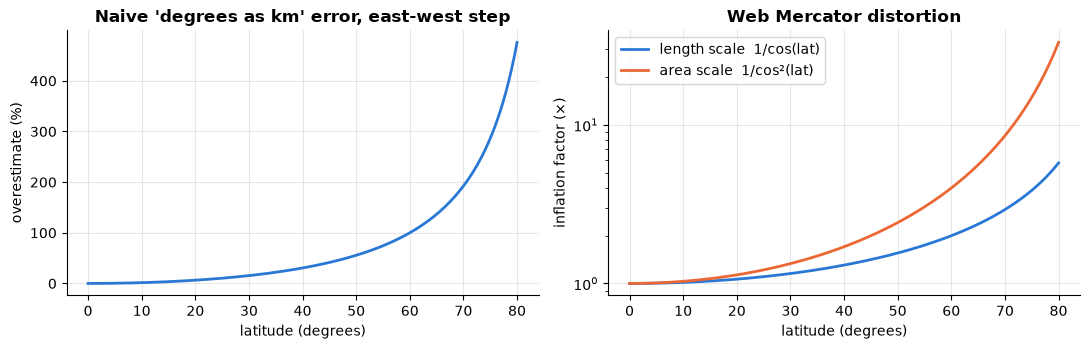

lat  0: 1 deg lon =  111.2 km | Mercator area inflation x 1.00
lat 30: 1 deg lon =   96.3 km | Mercator area inflation x 1.33
lat 50: 1 deg lon =   71.5 km | Mercator area inflation x 2.42
lat 60: 1 deg lon =   55.6 km | Mercator area inflation x 4.00
lat 72: 1 deg lon =   34.4 km | Mercator area inflation x10.47
UTM zone for longitude 10E: 32 -> EPSG:32632 (WGS 84 / UTM zone 32N)


In [3]:
# Projections distort: plot (left) the naive error for a short east-west step, (right) Web Mercator inflation
lat = np.linspace(0, 80, 161)
step_true = haversine_km(lat, 0.0, lat, 0.01)               # 0.01 degree east-west at each latitude
step_naive = naive_degree_km(lat, 0.0, lat, 0.01)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(lat, 100 * (step_naive - step_true) / step_true, color=PALETTE[0])
ax[0].set(title="Naive 'degrees as km' error, east-west step", xlabel="latitude (degrees)",
          ylabel="overestimate (%)")
ax[1].plot(lat, 1 / np.cos(np.radians(lat)), label="length scale  1/cos(lat)", color=PALETTE[0])
ax[1].plot(lat, 1 / np.cos(np.radians(lat)) ** 2, label="area scale  1/cos²(lat)", color=PALETTE[1])
ax[1].set(title="Web Mercator distortion", xlabel="latitude (degrees)", ylabel="inflation factor (×)", yscale="log")
ax[1].legend()
plt.tight_layout(); plt.show()
for L in (0, 30, 50, 60, 72):
    print(f"lat {L:2d}: 1 deg lon = {KM_PER_DEG*math.cos(math.radians(L)):6.1f} km | Mercator area inflation x{1/math.cos(math.radians(L))**2:5.2f}")
print("UTM zone for longitude 10E:", int((10 + 180) // 6) + 1, "-> EPSG:32632 (WGS 84 / UTM zone 32N)")

**What just happened?** The naive error for an east–west step is $1/\cos\varphi - 1$: zero at the equator, +56% at 50° and +100% at 60°. Web Mercator draws lengths $1/\cos\varphi$ too long and areas $1/\cos^2\varphi$ too large: at Greenland's latitude (about 72°) areas look about 10 times too big. For local work we project to a metric CRS (UTM, or the local equirectangular projection below) and then use ordinary Euclidean geometry in kilometres.

Next we place a **synthetic city** at 50°N, 10°E (made-up data, no real place is modelled) and write the local projection both ways.

In [4]:
LAT0, LON0 = 50.0, 10.0                                  # centre of our synthetic city
COS0 = math.cos(math.radians(LAT0))

def to_xy(lat, lon):
    """Local equirectangular projection: degrees -> km east (x) and km north (y) of the centre."""
    x = R_EARTH_KM * np.radians(np.asarray(lon) - LON0) * COS0
    y = R_EARTH_KM * np.radians(np.asarray(lat) - LAT0)
    return x, y

def to_latlon(x, y):
    """Inverse of to_xy: km offsets -> degrees."""
    lat = LAT0 + np.degrees(np.asarray(y) / R_EARTH_KM)
    lon = LON0 + np.degrees(np.asarray(x) / (R_EARTH_KM * COS0))
    return lat, lon

# How good is the flat approximation inside a 20 km city? Compare with haversine on random pairs.
xa, ya, xb, yb = rng.uniform(-10, 10, (4, 5000))
la, lo = to_latlon(xa, ya); lb, lob = to_latlon(xb, yb)
d_flat = np.hypot(xa - xb, ya - yb)
d_true = haversine_km(la, lo, lb, lob)
rel = np.abs(d_flat - d_true) / d_true
print(f"local projection vs haversine on 5,000 pairs inside the city: "
      f"max relative error {100*rel.max():.3f}%, mean {100*rel.mean():.4f}%")
assert rel.max() < 0.005

local projection vs haversine on 5,000 pairs inside the city: max relative error 0.185%, mean 0.0359%


**What just happened?** Inside a 20 km × 20 km city the local projection is within a fraction of a percent of the haversine distance, so from now on we can work in kilometres with ordinary Euclidean formulas. This is exactly what GIS practitioners do: **project first, then compute**. The error grows with the size of the area, which is why national maps use UTM zones or other carefully chosen projections.

---
## 2. Spatial indexing: grid, geohash and Ball tree

> 💬 **In plain English:** to find "all drivers within 500 m" among millions, do not measure the distance to every driver. Put them into labelled boxes first, then only look inside the nearby boxes.

**Intuition.** A library does not search every shelf for a book; it uses the catalogue number to go to the right aisle. A **spatial index** is a catalogue for locations.

**Definitions.**
- A **grid index** cuts the plane into square cells of side $c$ and stores, for each cell, the points inside it. A radius-$r$ query only needs the cells within $\lceil r/c \rceil$ cells of the query.
- A **geohash** encodes a (lat, lon) pair as a short string by repeatedly halving the longitude and latitude ranges and interleaving the resulting bits (longitude first), then writing 5 bits per character in base 32 (`0123456789bcdefghjkmnpqrstuvwxyz`, no a, i, l, o). Points that share a **prefix** lie in the same cell, so a database index on the string becomes a spatial index. Each extra character makes the cell 32 times smaller.
- **Tree indexes**: KD-trees split on one coordinate at a time; **Ball trees** split into nested balls and work with any true metric, including haversine. R-trees (used by PostGIS and SQLite's R*Tree module) index rectangles and polygons.

**Worked example by hand** (first 5 bits of a geohash for 42.6°N, 5.6°W):

| bit | coordinate | interval before | midpoint | value ≥ mid? | bit |
|---|---|---|---|---|---|
| 1 | lon −5.6 | [−180, 180] | 0 | no | 0 |
| 2 | lat 42.6 | [−90, 90] | 0 | yes | 1 |
| 3 | lon | [−180, 0] | −90 | yes | 1 |
| 4 | lat | [0, 90] | 45 | no | 0 |
| 5 | lon | [−90, 0] | −45 | yes | 1 |

Bits `01101` = 13, and character 13 of the base-32 alphabet is `e`. Continuing gives `ezs42`.

In [5]:
B32 = "0123456789bcdefghjkmnpqrstuvwxyz"            # geohash alphabet (no a, i, l, o)

def geohash_encode(lat, lon, precision=7):
    """Encode (lat, lon) in degrees as a geohash string of `precision` characters."""
    lat_rng, lon_rng = [-90.0, 90.0], [-180.0, 180.0]
    bits, use_lon = [], True                          # even bits are longitude, odd bits latitude
    while len(bits) < 5 * precision:
        rng_, v = (lon_rng, lon) if use_lon else (lat_rng, lat)
        mid = (rng_[0] + rng_[1]) / 2
        if v >= mid:
            bits.append(1); rng_[0] = mid             # keep the upper half
        else:
            bits.append(0); rng_[1] = mid             # keep the lower half
        use_lon = not use_lon
    out = []
    for i in range(0, len(bits), 5):                  # 5 bits -> one base-32 character
        val = 0
        for b in bits[i:i + 5]:
            val = 2 * val + b
        out.append(B32[val])
    return "".join(out)

def geohash_decode_bbox(gh):
    """Return the cell (lat_min, lat_max, lon_min, lon_max) of a geohash."""
    lat_rng, lon_rng, use_lon = [-90.0, 90.0], [-180.0, 180.0], True
    for ch in gh:
        val = B32.index(ch)
        for shift in range(4, -1, -1):                # read the 5 bits, most significant first
            bit = (val >> shift) & 1
            rng_ = lon_rng if use_lon else lat_rng
            mid = (rng_[0] + rng_[1]) / 2
            if bit: rng_[0] = mid
            else:   rng_[1] = mid
            use_lon = not use_lon
    return lat_rng[0], lat_rng[1], lon_rng[0], lon_rng[1]

# Known values (from the geohash specification examples)
assert geohash_encode(42.6, -5.6, 5) == "ezs42"
assert geohash_encode(57.64911, 10.40744, 11) == "u4pruydqqvj"
# Round trip: every point lies inside its own decoded cell
for _ in range(1000):
    la, lo = rng.uniform(-90, 90), rng.uniform(-180, 180)
    a, b, c, d = geohash_decode_bbox(geohash_encode(la, lo, 8))
    assert a <= la <= b and c <= lo <= d
print("geohash encoder/decoder pass the known examples and 1,000 round trips")

rows = []
for p in range(1, 10):
    a, b, c, d = geohash_decode_bbox("u" * p)          # cell size does not depend on which cell
    h_km = (b - a) * KM_PER_DEG
    w_eq = (d - c) * KM_PER_DEG
    rows.append({"precision": p, "cell height": f"{h_km:,.3f} km",
                 "cell width @ equator": f"{w_eq:,.3f} km",
                 "cell width @ 50N": f"{w_eq*COS0:,.3f} km"})
print(pd.DataFrame(rows).to_string(index=False))

geohash encoder/decoder pass the known examples and 1,000 round trips
 precision  cell height cell width @ equator cell width @ 50N
         1 5,003.779 km         5,003.779 km     3,216.367 km
         2   625.472 km         1,250.945 km       804.092 km
         3   156.368 km           156.368 km       100.511 km
         4    19.546 km            39.092 km        25.128 km
         5     4.887 km             4.887 km         3.141 km
         6     0.611 km             1.222 km         0.785 km
         7     0.153 km             0.153 km         0.098 km
         8     0.019 km             0.038 km         0.025 km
         9     0.005 km             0.005 km         0.003 km


**What just happened?** Each character adds 5 bits, alternately splitting longitude and latitude, so the cell shrinks by a factor of 32 per character: precision 5 is about 4.9 km, precision 6 about 1.2 km × 0.6 km, precision 7 about 153 m. Our encoder reproduces the published examples (`ezs42`, `u4pruydqqvj`).

**Complexity:** encoding and decoding are $O(p)$ for precision $p$.

> ⚠️ **Common mistake:** "same prefix ⇒ close" is true, but "close ⇒ same prefix" is **false**. Two points 1 m apart on either side of a cell boundary (for example the equator or the Greenwich meridian) can have completely different geohashes. A radius query must always also search the **8 neighbouring cells**.

In [6]:
# Edge effect: two points under 2 metres apart across the Greenwich meridian
print(geohash_encode(51.4779, -0.00001, 7), "vs", geohash_encode(51.4779, 0.00001, 7),
      f"(distance {1000*haversine_km(51.4779, -0.00001, 51.4779, 0.00001):.1f} m)")

class GridIndex:
    """Uniform grid over projected km coordinates: cell (i, j) -> list of point ids."""
    def __init__(self, lat, lon, cell_km):
        self.lat, self.lon, self.c = np.asarray(lat), np.asarray(lon), cell_km
        x, y = to_xy(lat, lon)
        self.cells = {}
        for idx, key in enumerate(zip(np.floor(x / cell_km).astype(int), np.floor(y / cell_km).astype(int))):
            self.cells.setdefault(key, []).append(idx)
    def query_radius(self, qlat, qlon, r_km):
        """Ids of points within r_km of the query (exact: candidates are filtered by haversine)."""
        qx, qy = to_xy(qlat, qlon)
        i0, j0, k = int(math.floor(qx / self.c)), int(math.floor(qy / self.c)), int(math.ceil(r_km / self.c))
        cand = [p for i in range(i0 - k, i0 + k + 1) for j in range(j0 - k, j0 + k + 1)
                for p in self.cells.get((i, j), [])]
        if not cand:
            return np.array([], dtype=int), 0
        cand = np.array(cand)
        d = haversine_km(qlat, qlon, self.lat[cand], self.lon[cand])
        return np.sort(cand[d <= r_km]), len(cand)

# 30,000 synthetic "drivers" in the city and 300 "riders" asking for drivers within 0.5 km
N_PTS, N_Q, RADIUS = 30_000, 300, 0.5
px, py = rng.uniform(-10, 10, N_PTS), rng.uniform(-10, 10, N_PTS)
plat, plon = to_latlon(px, py)
qlat, qlon = to_latlon(rng.uniform(-9, 9, N_Q), rng.uniform(-9, 9, N_Q))

t = time.perf_counter()
brute = [np.flatnonzero(haversine_km(a, b, plat, plon) <= RADIUS) for a, b in zip(qlat, qlon)]
t_brute = time.perf_counter() - t

grid = GridIndex(plat, plon, cell_km=RADIUS)
t = time.perf_counter()
grid_res = [grid.query_radius(a, b, RADIUS) for a, b in zip(qlat, qlon)]
t_grid = time.perf_counter() - t

tree = BallTree(np.radians(np.c_[plat, plon]), metric="haversine")    # [lat, lon] in radians!
t = time.perf_counter()
tree_res = tree.query_radius(np.radians(np.c_[qlat, qlon]), r=RADIUS / R_EARTH_KM)
t_tree = time.perf_counter() - t

for b, (g, _), tr in zip(brute, grid_res, tree_res):
    assert np.array_equal(b, g) and np.array_equal(b, np.sort(tr))
avg_found = np.mean([len(b) for b in brute])
avg_cand = np.mean([c for _, c in grid_res])
print(f"all three methods return identical neighbour sets for {N_Q} queries "
      f"(on average {avg_found:.1f} drivers within {RADIUS} km)")
print(pd.DataFrame({
    "method": ["brute force (all distances)", "grid index (from scratch)", "BallTree (haversine, sklearn)"],
    "distance computations per query": [N_PTS, round(avg_cand), "about log n nodes + results"],
    "time for all queries (s)": [round(t_brute, 3), round(t_grid, 3), round(t_tree, 3)],
}).to_string(index=False))

# k nearest neighbours with the Ball tree, checked against brute force
dist, ind = tree.query(np.radians(np.c_[qlat[:50], qlon[:50]]), k=5)
for q in range(50):
    d_all = haversine_km(qlat[q], qlon[q], plat, plon)
    assert np.allclose(np.sort(d_all)[:5], dist[q] * R_EARTH_KM)
print("BallTree 5-NN distances match brute force on 50 queries")

gcpuzgr vs u10hb52 (distance 1.4 m)


all three methods return identical neighbour sets for 300 queries (on average 59.0 drivers within 0.5 km)
                       method distance computations per query  time for all queries (s)
  brute force (all distances)                           30000                     0.975
    grid index (from scratch)                             170                     0.043
BallTree (haversine, sklearn)     about log n nodes + results                     0.010
BallTree 5-NN distances match brute force on 50 queries


**What just happened?** The two points less than 2 m apart across the Greenwich meridian get geohashes starting with different letters (`g` and `u`), the edge effect in action. Brute force computed 30,000 distances per query. The grid index looked only at points in the 3 × 3 block of 0.5 km cells around the query (about 9/1600 of the city, so roughly 170 candidates), then filtered them exactly. The Ball tree prunes whole balls of points that are too far away. All three returned **identical** answers; the indexes are much faster (exact timings depend on the machine, and the Python grid loop has interpreter overhead that a compiled index would not).

**Complexity.** Brute force: $O(n)$ per query. Grid: $O(k + m)$ where $m$ is the number of candidates in the searched cells; excellent for roughly uniform data, poor when many points crowd into a few cells. Ball/KD-tree: build $O(n\log n)$, query about $O(\log n + k)$ in low dimensions.

> 🎓 **Exam / interview tip:** "How would you find the nearest available driver among 1 million?" Answer: a spatial index (geohash/H3 cells in a key–value store, or a tree index), query the rider's cell **plus neighbours**, rank candidates by haversine or, better, by road ETA (section 7). Uber's **H3** uses hexagons because all 6 neighbours of a hexagon are at the same distance, unlike the 8 neighbours of a square.

---
## 3. Spatial features for a house-price model

> 💬 **In plain English:** a model cannot "see" a map. We turn location into useful numbers: how far to the centre, how far to the nearest station, how many parks are within walking distance, how dense the area is, and what nearby houses sell for.

**Definitions.**
- **Distance-to-POI feature:** the distance from each row to the nearest point of interest of a type (station, school, hospital). Computed with a nearest-neighbour index.
- **Count-within-radius feature:** the number of POIs within $r$ km (e.g. parks within 500 m).
- **Neighbourhood aggregate:** a statistic (mean, median) of nearby rows, e.g. the mean price of the 10 nearest *training* houses. Using the target this way is **spatial target encoding** and must be computed only from training data, otherwise it leaks the answer.
- **Kernel density estimate (KDE):** a smooth "how crowded is it here" score, $\hat f(\mathbf s) \propto \sum_i K\big(d(\mathbf s, \mathbf s_i)/h\big)$, with bandwidth $h$.

We generate a synthetic city: 3,000 houses, a central business district (CBD), two metro lines with 24 stations, and 12 parks. The (hidden) true log-price depends on size, age, distance to the CBD, closeness to a station, a park within 500 m, and a smooth **spatial random field** (unmeasured neighbourhood quality).

         lat     lon       x       y  size_m2  rooms     age  log_price  price_k
mean  50.001   9.997  -0.183   0.079   87.304  3.101  39.447      5.338  217.451
std    0.044   0.067   4.770   4.851   22.714  1.095  23.060      0.297   66.023
min   49.910   9.860 -10.000 -10.000   33.000  1.000   0.000      4.295   73.300
max   50.090  10.140  10.000  10.000  210.000  8.000  79.000      6.317  553.900


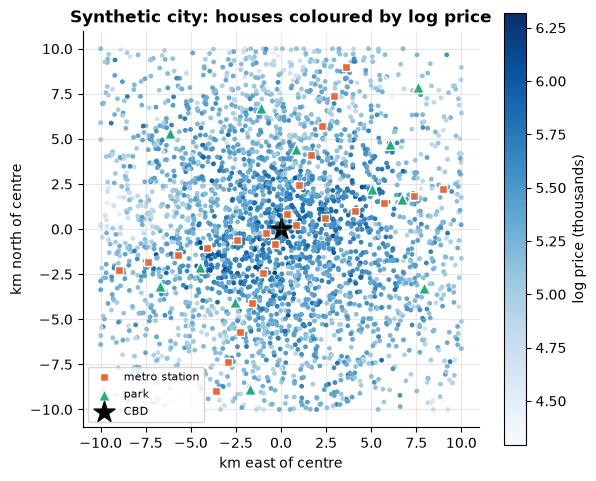

In [7]:
N_HOUSES = 3000
# Houses: 60% clustered around the centre, 40% spread over the city; clipped to a 20 km square
hx = np.where(rng.random(N_HOUSES) < 0.6, rng.normal(0, 4, N_HOUSES), rng.uniform(-10, 10, N_HOUSES)).clip(-10, 10)
hy = np.where(rng.random(N_HOUSES) < 0.6, rng.normal(0, 4, N_HOUSES), rng.uniform(-10, 10, N_HOUSES)).clip(-10, 10)
hlat, hlon = to_latlon(hx, hy)

# Two straight metro lines through the centre, a station roughly every 1.6 km
t_ = np.linspace(-9, 9, 12)
st_x = np.r_[t_, 0.4 * t_[np.abs(t_) > 0.5]]              # line 1: west-east; line 2: tilted north-south
st_y = np.r_[0.25 * t_, t_[np.abs(t_) > 0.5]]
st_lat, st_lon = to_latlon(st_x, st_y)
park_x, park_y = rng.uniform(-9, 9, 12), rng.uniform(-9, 9, 12)
park_lat, park_lon = to_latlon(park_x, park_y)

# Hidden neighbourhood quality: a smooth random field made of 60 Gaussian bumps (length scale 1.5 km)
bump_c = rng.uniform(-11, 11, (60, 2)); bump_a = rng.normal(0, 0.2, 60)
def quality_field(x, y):
    d2 = (np.asarray(x)[..., None] - bump_c[:, 0]) ** 2 + (np.asarray(y)[..., None] - bump_c[:, 1]) ** 2
    return (bump_a * np.exp(-d2 / (2 * 1.5 ** 2))).sum(-1)

size = rng.lognormal(np.log(85), 0.25, N_HOUSES).round()   # m^2
rooms = np.clip(np.round(size / 28 + rng.normal(0, 0.7, N_HOUSES)), 1, 8)
age = rng.integers(0, 80, N_HOUSES)
d_cbd_true = np.hypot(hx, hy)
d_st_true = cdist(np.c_[hx, hy], np.c_[st_x, st_y]).min(1)
park500_true = (cdist(np.c_[hx, hy], np.c_[park_x, park_y]) <= 0.5).any(1)
log_price = (5.6 + 0.8 * np.log(size / 85) - 0.002 * age - 0.035 * d_cbd_true
             + 0.25 * np.exp(-d_st_true / 0.6) + 0.08 * park500_true
             + quality_field(hx, hy) + rng.normal(0, 0.08, N_HOUSES))
houses = pd.DataFrame({"lat": hlat, "lon": hlon, "x": hx, "y": hy, "size_m2": size, "rooms": rooms,
                       "age": age, "log_price": log_price, "price_k": np.exp(log_price).round(1)})
print(houses.describe().loc[["mean", "std", "min", "max"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(6.4, 5.6))
sc = ax.scatter(hx, hy, c=log_price, s=6, cmap="Blues")
ax.scatter(st_x, st_y, marker="s", s=40, color=PALETTE[1], edgecolor="white", label="metro station")
ax.scatter(park_x, park_y, marker="^", s=70, color=PALETTE[2], edgecolor="white", label="park")
ax.scatter([0], [0], marker="*", s=250, color="black", label="CBD")
plt.colorbar(sc, ax=ax, label="log price (thousands)")
ax.set(title="Synthetic city: houses coloured by log price", xlabel="km east of centre", ylabel="km north of centre")
ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=8); plt.show()

**What just happened?** Darker dots are more expensive. You can see the expensive centre and darker or lighter blotches that come from the hidden quality field: nearby houses look alike. (The station and park effects are real but smaller, so they are hard to spot by eye; the model will find them.) This visible clustering is **spatial autocorrelation**, the topic of section 4.

Now we build the features from the **lat/lon columns only**, as a real pipeline would (the true x, y, distances and field are hidden from the model).

In [8]:
def latlon_rad(lat, lon):
    return np.radians(np.c_[lat, lon])                     # sklearn haversine wants [lat, lon] radians

station_tree = BallTree(latlon_rad(st_lat, st_lon), metric="haversine")
park_tree = BallTree(latlon_rad(park_lat, park_lon), metric="haversine")
# KDE of station locations with a 1 km bandwidth (haversine metric needs a Ball tree)
station_kde = KernelDensity(bandwidth=1.0 / R_EARTH_KM, metric="haversine", kernel="gaussian",
                            algorithm="ball_tree").fit(latlon_rad(st_lat, st_lon))

def static_spatial_features(df):
    """Features that use only the location and public POI data (no target)."""
    X = latlon_rad(df["lat"], df["lon"])
    out = pd.DataFrame(index=df.index)
    out["dist_cbd_km"] = haversine_km(df["lat"], df["lon"], LAT0, LON0)
    out["dist_station_km"] = station_tree.query(X, k=1)[0][:, 0] * R_EARTH_KM
    out["parks_within_500m"] = park_tree.query_radius(X, r=0.5 / R_EARTH_KM, count_only=True)
    out["station_density"] = station_kde.score_samples(X)          # log density (relative units)
    return out

def neighbour_price_feature(df, train_idx, apply_idx, k=10):
    """Mean log price of the k nearest TRAINING houses (excluding the house itself)."""
    tr = df.loc[train_idx]
    t = BallTree(latlon_rad(tr["lat"], tr["lon"]), metric="haversine")
    ap = df.loc[apply_idx]
    in_train = np.isin(apply_idx, train_idx)
    _, ind = t.query(latlon_rad(ap["lat"], ap["lon"]), k=k + 1)
    yv = tr["log_price"].to_numpy()
    # if the row itself is in the training set its own price is the nearest neighbour: drop column 0
    vals = np.where(in_train[:, None], yv[ind[:, 1:]], yv[ind[:, :k]])
    return vals.mean(1)

static = static_spatial_features(houses)
# Sanity check: the engineered distances equal the hidden true ones (up to the tiny projection error)
assert np.allclose(static["dist_station_km"], d_st_true, rtol=0.01, atol=0.005)
assert np.array_equal(static["parks_within_500m"] > 0, park500_true) or \
       (static["parks_within_500m"].gt(0) != park500_true).sum() <= 3
print(static.describe().loc[["mean", "min", "max"]].round(3).to_string())

# A from-scratch Gaussian KDE agrees with sklearn up to a constant factor (the normalisation)
d_km = haversine_km(houses["lat"].to_numpy()[:, None], houses["lon"].to_numpy()[:, None], st_lat[None], st_lon[None])
kde_ours = np.exp(-0.5 * (d_km / 1.0) ** 2).sum(1)
ratio = kde_ours / np.exp(static["station_density"].to_numpy())
print(f"KDE ratio ours/sklearn: min {ratio.min():.4g}, max {ratio.max():.4g} (constant => same shape)")
assert np.allclose(ratio, ratio.mean(), rtol=1e-3)

      dist_cbd_km  dist_station_km  parks_within_500m  station_density
mean        6.148            2.744              0.022            6.755
min         0.085            0.019              0.000          -60.623
max        14.136           12.130              1.000           13.567
KDE ratio ours/sklearn: min 3.715e-06, max 3.715e-06 (constant => same shape)


**What just happened?** Four static features came from two Ball-tree queries, one radius count and a KDE. They are computed from public POI locations only, so they are safe to use anywhere. The neighbour-price feature uses the **target**, so the function takes `train_idx` and only ever looks at training prices (and never at a house's own price). Our from-scratch KDE is a constant multiple of scikit-learn's, so the two have the same shape; only the normalising constant differs.

Now compare three feature sets with a gradient-boosting model. For now we use a simple random 80/20 split; section 4 shows why that is too optimistic.

In [9]:
BASE = ["size_m2", "rooms", "age"]

def build_X(df, feature_set, train_idx, apply_idx):
    X = df.loc[apply_idx, BASE].copy()
    if feature_set in ("B: + lat/lon", "C: + spatial features"):
        X[["lat", "lon"]] = df.loc[apply_idx, ["lat", "lon"]]
    if feature_set == "C: + spatial features":
        X = X.join(static.loc[apply_idx])
        X["nbr_mean_log_price"] = neighbour_price_feature(df, train_idx, apply_idx)
    return X

def fit_predict(df, feature_set, train_idx, test_idx, seed=0):
    model = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.1, max_leaf_nodes=15, random_state=seed)
    model.fit(build_X(df, feature_set, train_idx, train_idx), df.loc[train_idx, "log_price"])
    return model.predict(build_X(df, feature_set, train_idx, test_idx))

FEATURE_SETS = ["A: size/rooms/age", "B: + lat/lon", "C: + spatial features"]
perm = rng.permutation(N_HOUSES)
tr_idx, te_idx = np.sort(perm[:2400]), np.sort(perm[2400:])
y_te = houses.loc[te_idx, "log_price"].to_numpy()
rows = []
for fs in FEATURE_SETS:
    pred = fit_predict(houses, fs, tr_idx, te_idx)
    rmse = np.sqrt(np.mean((pred - y_te) ** 2))
    mape = np.mean(np.abs(np.exp(pred) - np.exp(y_te)) / np.exp(y_te))
    rows.append({"features": fs, "RMSE (log price)": round(rmse, 4), "MAPE price": f"{100*mape:.1f}%"})
holdout_table = pd.DataFrame(rows)
print(holdout_table.to_string(index=False))

             features  RMSE (log price) MAPE price
    A: size/rooms/age            0.2222      18.2%
         B: + lat/lon            0.1016       8.1%
C: + spatial features            0.0977       7.7%


**What just happened?** Without location (A) the model can only use size, rooms and age, so it misses everything that depends on *where* the house is. Adding raw lat/lon (B) lets the trees carve the map into rectangles and learn local price levels. The engineered features (C) are slightly better again. They describe the **mechanism** (distance to transport, parks, local price level) directly, so the trees need far fewer splits to use them. On a random split the gap between B and C is small; the real advantage of mechanistic features appears in section 4, when we predict far away from the training data.

**Complexity of feature building:** with a tree index, $O(n\log m)$ for $n$ houses and $m$ POIs, instead of $O(nm)$ for all pairwise distances.

> ⚠️ **Common mistake:** computing "mean price of the 10 nearest houses" on the **whole** dataset before splitting. Then each test house's feature contains its own neighbours' test prices (and possibly its own price). The validation score looks great and production accuracy collapses. Always compute target-based features inside the training fold.

---
## 4. Spatial autocorrelation and spatial block cross-validation

> 💬 **In plain English:** Tobler's first law of geography says "everything is related to everything else, but near things are more related than distant things". Moran's I measures how true that is for your data, and it explains why a normal random train/test split can lie to you.

**Definition.** Given values $x_1, \dots, x_n$ at locations and a **spatial weights matrix** $W$ ($w_{ij} > 0$ if $i$ and $j$ are neighbours, $w_{ii} = 0$), with $z_i = x_i - \bar x$ and $S_0 = \sum_{ij} w_{ij}$, **Moran's I** is

$$I = \frac{n}{S_0}\,\frac{\sum_{i}\sum_{j} w_{ij} z_i z_j}{\sum_i z_i^2}.$$

- $I > 0$: neighbours have similar values (clustering). $I < 0$: neighbours are dissimilar (a checkerboard). Under no spatial pattern, $E[I] = -1/(n-1)$, close to 0.
- Significance is usually tested by a **permutation test**: shuffle the values over the locations many times and see how often the shuffled $I$ is as large as the observed one.

**Worked example by hand.** Four cells in a row, neighbours = cells that touch (so $w_{12} = w_{21} = w_{23} = w_{32} = w_{34} = w_{43} = 1$, $S_0 = 6$).

| values | $z$ | $\sum_{ij} w_{ij} z_i z_j$ | $\sum z_i^2$ | $I = \frac{4}{6}\cdot\frac{\text{num}}{\text{den}}$ |
|---|---|---|---|---|
| 1, 2, 3, 4 (smooth) | −1.5, −0.5, 0.5, 1.5 | $2(0.75 - 0.25 + 0.75) = 2.5$ | 5 | **+0.333** |
| 1, 4, 1, 4 (alternating) | −1.5, 1.5, −1.5, 1.5 | $2(-2.25 \times 3) = -13.5$ | 9 | **−1.000** |

The expected value with no pattern is $-1/3$, so the smooth row is clustered and the alternating row is perfectly dispersed.

In [10]:
def morans_i(values, W):
    """Moran's I for values (n,) and a spatial weights matrix W (n x n, dense or scipy sparse, zero diagonal)."""
    z = np.asarray(values, float) - np.mean(values)
    num = z @ (W @ z)                    # sum_ij w_ij z_i z_j
    return len(z) / W.sum() * num / (z @ z)

def moran_permutation_test(values, W, n_perm=499, seed=0):
    """Observed I and a one-sided pseudo p-value (positive autocorrelation) from random relabelling."""
    r = np.random.default_rng(seed)
    obs = morans_i(values, W)
    sims = np.array([morans_i(r.permutation(values), W) for _ in range(n_perm)])
    p = (1 + np.sum(sims >= obs)) / (n_perm + 1)
    return obs, p, sims

W_line = np.array([[0, 1, 0, 0], [1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0]], float)
print("smooth 1,2,3,4      I =", round(morans_i([1, 2, 3, 4], W_line), 4))
print("alternating 1,4,1,4 I =", round(morans_i([1, 4, 1, 4], W_line), 4))
assert np.isclose(morans_i([1, 2, 3, 4], W_line), 1 / 3) and np.isclose(morans_i([1, 4, 1, 4], W_line), -1)

def knn_weights(lat, lon, k=8):
    """Sparse binary k-nearest-neighbour weights (haversine), symmetrised so that W = W^T."""
    t = BallTree(latlon_rad(lat, lon), metric="haversine")
    _, ind = t.query(latlon_rad(lat, lon), k=k + 1)
    n = len(lat)
    rows_, cols_ = np.repeat(np.arange(n), k), ind[:, 1:].ravel()      # skip self (column 0)
    W = sparse.csr_matrix((np.ones(n * k), (rows_, cols_)), shape=(n, n))
    W = ((W + W.T) > 0).astype(float)
    return W

W_h = knn_weights(houses["lat"], houses["lon"], k=8)
obs, p, sims = moran_permutation_test(houses["log_price"].to_numpy(), W_h)
print(f"\nHouse log prices (8-NN weights): Moran's I = {obs:.3f}, permutation p = {p:.3f}, "
      f"shuffled I mean = {sims.mean():.4f} (theory {-1/(N_HOUSES-1):.4f})")

smooth 1,2,3,4      I = 0.3333
alternating 1,4,1,4 I = -1.0



House log prices (8-NN weights): Moran's I = 0.426, permutation p = 0.002, shuffled I mean = -0.0006 (theory -0.0003)


**What just happened?** Our from-scratch Moran's I reproduces the hand calculation (+1/3 and −1). On the house prices it is strongly positive, and none of the 499 shuffles came close, so the p-value is the smallest possible with 499 permutations ($1/500 = 0.002$). The shuffled values average about $-1/(n-1) \approx 0$, as the theory says.

**Complexity:** with a sparse weights matrix holding $nk$ non-zeros, one $I$ costs $O(nk)$, and a permutation test with $P$ shuffles costs $O(Pnk)$.

### How far does the similarity reach? A Moran correlogram
We compute Moran's I using "neighbours = pairs whose distance falls in a band" for bands of increasing distance. The distance where $I$ drops to about 0 is the **range** of autocorrelation.

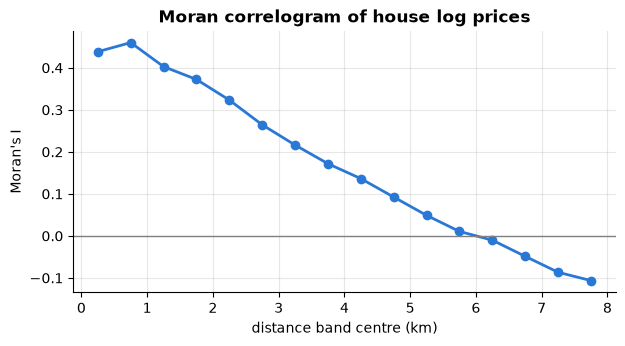

Moran's I by band: [ 0.438  0.46   0.403  0.372  0.323  0.264  0.216  0.172  0.136  0.092
  0.049  0.011 -0.01  -0.049 -0.087 -0.106]
I first drops below 0.1 in the band centred at 4.75 km


In [11]:
sub = rng.choice(N_HOUSES, 1500, replace=False)                 # subsample: keeps the n^2 matrix small
D_sub = cdist(houses.loc[sub, ["x", "y"]], houses.loc[sub, ["x", "y"]])
bands = np.arange(0, 8.5, 0.5)
corr = []
for lo, hi in zip(bands[:-1], bands[1:]):
    Wb = ((D_sub > lo) & (D_sub <= hi)).astype(float)
    np.fill_diagonal(Wb, 0)
    corr.append(morans_i(houses.loc[sub, "log_price"].to_numpy(), Wb))
mid = (bands[:-1] + bands[1:]) / 2
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(mid, corr, marker="o", color=PALETTE[0])
ax.axhline(0, color="gray", lw=1)
ax.set(title="Moran correlogram of house log prices", xlabel="distance band centre (km)", ylabel="Moran's I")
plt.show()
first_small = mid[np.argmax(np.array(corr) < 0.1)]
print("Moran's I by band:", np.round(corr, 3))
print(f"I first drops below 0.1 in the band centred at {first_small} km")

**What just happened?** Houses within half a kilometre are strongly alike ($I \approx 0.44$); similarity fades steadily with distance, drops below 0.1 at about 5 km and turns slightly negative beyond about 6 km. So the autocorrelation **range** is roughly 4–5 km. (Part of the long-range structure is the CBD trend: the centre is expensive, the edges are cheap, so far-apart pairs are often on opposite sides of a gradient and $I$ even goes slightly negative.)

### Why random cross-validation leaks
With random K-fold, a test house almost always has a training house a few hundred metres away, inside the autocorrelation range. A flexible model can simply **memorise local price levels** from lat/lon and copy them to the neighbour. That is fine if, in production, you will always predict *inside* areas you have data for. It is badly optimistic if you will predict in a **new district or a new city**.

**Definition.** **Spatial block cross-validation** partitions space into blocks (here squares of side $b$ km), assigns whole blocks to folds, and so forces test points to be far from most training points. Choose $b$ at least as large as the autocorrelation range. A stricter variant adds a **buffer**: training points within a distance $h$ of the test block are dropped.

We compare for feature sets B (raw lat/lon) and C (mechanistic spatial features):
- random 5-fold CV;
- spatial block 5-fold CV with several block sizes;
- the **real deployment test**: train on the city *except* a 6 km × 6 km district in the north-east, and predict that unseen district.

In [12]:
def kfold_random(n, k, seed=0):
    idx = np.random.default_rng(seed).permutation(n)
    return [np.sort(f) for f in np.array_split(idx, k)]

def kfold_spatial_blocks(x, y, block_km, k, seed=0):
    """Assign square blocks of side block_km (randomly) to k folds; returns test indices per fold."""
    bx = np.floor((np.asarray(x) + 10) / block_km).astype(int)
    by = np.floor((np.asarray(y) + 10) / block_km).astype(int)
    block_id = bx * 1000 + by
    blocks = np.random.default_rng(seed).permutation(np.unique(block_id))
    fold_of_block = {b: i % k for i, b in enumerate(blocks)}
    folds = np.array([fold_of_block[b] for b in block_id])
    return [np.flatnonzero(folds == f) for f in range(k)]

def cv_rmse(df, feature_set, test_folds):
    errs = []
    for te in test_folds:
        tr = np.setdiff1d(np.arange(len(df)), te)
        pred = fit_predict(df, feature_set, tr, te)
        errs.append((pred - df.loc[te, "log_price"].to_numpy()) ** 2)
    return float(np.sqrt(np.concatenate(errs).mean()))

# The deployment scenario: an unseen 6 km x 6 km district in the north-east
in_district = ((houses["x"] > 3) & (houses["y"] > 3)).to_numpy()
d_te, d_tr = np.flatnonzero(in_district), np.flatnonzero(~in_district)

t0 = time.perf_counter()
rows = []
for fs in FEATURE_SETS[1:]:
    row = {"features": fs, "random 5-fold": cv_rmse(houses, fs, kfold_random(N_HOUSES, 5))}
    for b in (1, 2, 4):
        row[f"block {b} km"] = cv_rmse(houses, fs, kfold_spatial_blocks(houses["x"], houses["y"], b, 5))
    pred = fit_predict(houses, fs, d_tr, d_te)
    row["unseen NE district (truth)"] = float(np.sqrt(np.mean((pred - houses.loc[d_te, "log_price"]) ** 2)))
    rows.append(row)
cv_table = pd.DataFrame(rows).set_index("features").round(4)
print("RMSE of log price (lower is better)")
print(cv_table.to_string())
print(f"({in_district.sum()} houses in the held-out district; computed in {time.perf_counter()-t0:.1f} s)")

RMSE of log price (lower is better)
                       random 5-fold  block 1 km  block 2 km  block 4 km  unseen NE district (truth)
features                                                                                            
B: + lat/lon                  0.0992      0.1047      0.1154      0.1412                      0.1404
C: + spatial features         0.0945      0.0992      0.1046      0.1186                      0.1353
(209 houses in the held-out district; computed in 21.8 s)


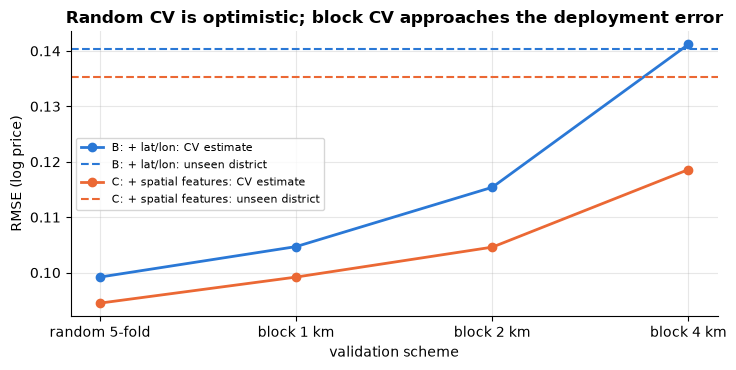

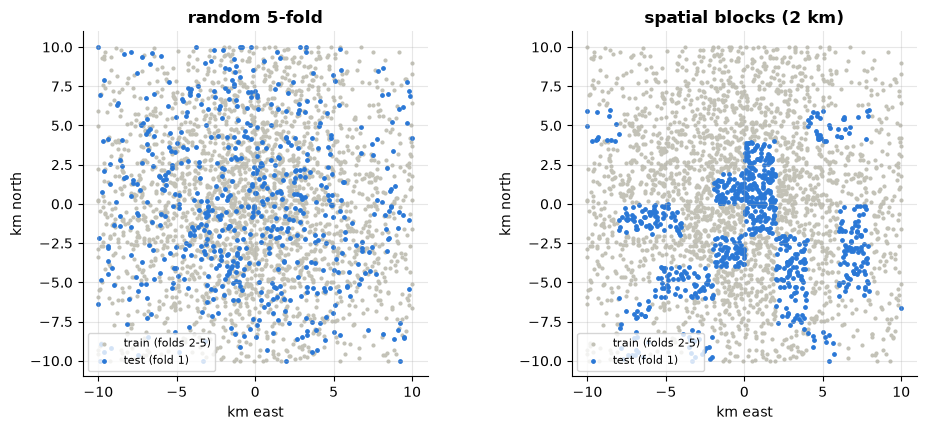

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
cols = list(cv_table.columns)
for i, fs in enumerate(cv_table.index):
    ax.plot(range(len(cols) - 1), cv_table.loc[fs, cols[:-1]], marker="o", color=PALETTE[i], label=f"{fs}: CV estimate")
    ax.axhline(cv_table.loc[fs, cols[-1]], color=PALETTE[i], ls="--", lw=1.5, label=f"{fs}: unseen district")
ax.set_xticks(range(len(cols) - 1), cols[:-1])
ax.set(title="Random CV is optimistic; block CV approaches the deployment error",
       ylabel="RMSE (log price)", xlabel="validation scheme")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# Show what the folds look like
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
for a, folds, title in [(ax[0], kfold_random(N_HOUSES, 5), "random 5-fold"),
                        (ax[1], kfold_spatial_blocks(houses["x"], houses["y"], 2, 5), "spatial blocks (2 km)")]:
    lab = np.zeros(N_HOUSES, int)
    for f, te in enumerate(folds):
        lab[te] = f
    mask0 = lab == 0
    a.scatter(houses["x"][~mask0], houses["y"][~mask0], s=4, color="#c3c2b7", label="train (folds 2-5)")
    a.scatter(houses["x"][mask0], houses["y"][mask0], s=6, color=PALETTE[0], label="test (fold 1)")
    a.set(title=title, xlabel="km east", ylabel="km north"); a.set_aspect("equal")
    a.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** Read the table row by row.
- For **B (raw lat/lon)**, random CV reports an RMSE of 0.099. As blocks grow, the CV error rises (0.105 → 0.115 → 0.141), and with 4 km blocks (about the autocorrelation range) it matches the error on the truly unseen north-east district (0.140). Random CV underestimated the deployment error by about 30%: the model had memorised neighbourhood levels by location, and random CV rewarded that.
- For **C (spatial features)**, every estimate is lower, because distance-to-station and distance-to-CBD carry over to new places; with 4 km blocks C beats B clearly (0.119 vs 0.141). The neighbour-price feature helps less when the neighbours are far away, so C's error also rises with block size. On the single held-out district C is only a little better than B (0.135 vs 0.140): one district is one noisy sample, which is exactly why we average over many blocks.
- The fold maps show the difference: random test points are sprinkled between training points; block test points form whole squares.

The exact numbers depend on the random city; the pattern is the lesson: **validate the way you will deploy.**

> ⚠️ **Common mistake:** using spatial block CV with tiny blocks (smaller than the autocorrelation range from the correlogram) or with random K-fold on **time series of locations** (sensors, stores). Both still leak.

> 🎓 **Exam / interview tip:** "Your geospatial model scored R² = 0.95 in CV but fails in a new city. Why?" Spatial autocorrelation + random CV ⇒ information leaks from neighbours; lat/lon features memorise local levels. Fix: spatial (block or buffered leave-one-out) CV, features that transfer (distances, densities, land use), and report the error on a geographically held-out region. Reference: Roberts et al. (2017), "Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure".

In [14]:
# Residual autocorrelation: a good spatial model leaves little spatial pattern in its errors
rows = []
folds = kfold_spatial_blocks(houses["x"], houses["y"], 2, 5)
for fs in FEATURE_SETS:
    res = np.zeros(N_HOUSES)
    for te in folds:
        tr = np.setdiff1d(np.arange(N_HOUSES), te)
        res[te] = houses.loc[te, "log_price"].to_numpy() - fit_predict(houses, fs, tr, te)
    I_res, p_res, _ = moran_permutation_test(res, W_h, n_perm=199)
    rows.append({"features": fs, "Moran's I of out-of-fold residuals": round(I_res, 3), "p-value": round(p_res, 3)})
print(pd.DataFrame(rows).to_string(index=False))

             features  Moran's I of out-of-fold residuals  p-value
    A: size/rooms/age                               0.776    0.005
         B: + lat/lon                               0.344    0.005
C: + spatial features                               0.215    0.005


**What just happened?** Moran's I of the residuals tells you how much spatial signal the model **left on the table**. Without location (A) the errors are strongly clustered ($I \approx 0.78$, even higher than for the prices themselves, because the size effect has been removed and what is left is almost purely "where"): whole neighbourhoods are all over- or under-predicted. Adding lat/lon cuts it to about 0.34, and the mechanistic features cut it most, to about 0.22. (With 199 shuffles the smallest possible p-value is 0.005.) Remaining positive $I$ means there is still unexplained neighbourhood structure (here, the hidden quality field), which a spatial random-effect, kriging of residuals (section 5) or a neighbour feature can absorb.

---
## 5. Spatial interpolation: IDW and Gaussian-process kriging

> 💬 **In plain English:** you have 60 air-quality sensors and want a full pollution map. Interpolation guesses the value between sensors, and kriging also tells you how unsure that guess is.

**Definitions.**
- **Inverse distance weighting (IDW):** $\hat z(\mathbf s) = \sum_i w_i z_i / \sum_i w_i$ with $w_i = d(\mathbf s, \mathbf s_i)^{-p}$. Simple, exact at the sensors, no uncertainty, and the power $p$ is a guess.
- **Semivariogram:** $\gamma(h) = \tfrac12 E\big[(Z(\mathbf s) - Z(\mathbf s + h))^2\big]$, half the expected squared difference between values $h$ apart. It starts near the **nugget** (measurement noise), rises, and flattens at the **sill** (total variance) after the **range**.
- **Kriging** is the best linear unbiased predictor under a covariance model; in ML language it is exactly **Gaussian-process regression** with a stationary kernel. For a covariance $k$ (e.g. RBF $k(h) = \sigma_f^2 e^{-h^2/2\ell^2}$) and noise $\sigma_n^2$:

$$\mu(\mathbf s_*) = m + \mathbf k_*^\top (K + \sigma_n^2 I)^{-1}(\mathbf z - m), \qquad \sigma^2(\mathbf s_*) = k(0) - \mathbf k_*^\top (K + \sigma_n^2 I)^{-1}\mathbf k_*.$$

  With a known mean $m$ this is **simple kriging**; **ordinary kriging** estimates the constant mean as part of the system. The semivariogram and the kernel are two views of one thing: $\gamma(h) = \sigma_n^2 + k(0) - k(h)$ for $h > 0$.

See [Gaussian processes from scratch](../../14_Mathematics/07_bayesian_ml.ipynb) (section 4), the [industry GP notebook](../04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb) and [kernel methods](../16_learning_theory/02_kernel_methods.ipynb) (the kernel–GP connection) for the background. Note: we interpolate in **projected kilometres**, so that "distance" means the same thing in every direction.

In [15]:
def pm25_field(x, y):
    """Hidden 'true' PM2.5 surface (micrograms per m^3): an industrial plume + a smooth regional pattern."""
    return (18 + 14 * np.exp(-((x - 4) ** 2 + (y + 3) ** 2) / (2 * 2.2 ** 2))
            + 4 * np.sin(x / 3.0) * np.cos(y / 4.0))

N_SENS = 60
sx, sy = rng.uniform(-10, 10, N_SENS), rng.uniform(-10, 10, N_SENS)
sz = pm25_field(sx, sy) + rng.normal(0, 0.8, N_SENS)                 # noisy sensor readings
S = np.c_[sx, sy]
gx, gy = np.meshgrid(np.linspace(-10, 10, 81), np.linspace(-10, 10, 81))
G = np.c_[gx.ravel(), gy.ravel()]
truth = pm25_field(G[:, 0], G[:, 1])

def idw(S_known, z_known, S_query, power=2.0):
    """Inverse distance weighting; returns the sensor value exactly at a sensor location."""
    d = cdist(S_query, S_known)
    w = 1.0 / np.maximum(d, 1e-12) ** power
    return (w @ z_known) / w.sum(1)

def gp_predict(S_tr, z_tr, S_te, ell, sf2, sn2):
    """GP regression / simple kriging with an RBF kernel, from scratch (Cholesky). Returns mean, latent variance."""
    m = z_tr.mean()                                           # plug-in mean (simple kriging)
    K = sf2 * np.exp(-cdist(S_tr, S_tr) ** 2 / (2 * ell ** 2)) + sn2 * np.eye(len(S_tr))
    L = np.linalg.cholesky(K)                                 # K = L L^T, stable solve
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, z_tr - m))
    Ks = sf2 * np.exp(-cdist(S_te, S_tr) ** 2 / (2 * ell ** 2))
    v = np.linalg.solve(L, Ks.T)
    return m + Ks @ alpha, sf2 - (v ** 2).sum(0)

# Fit the kernel hyperparameters by maximum marginal likelihood with sklearn, then reuse them
kernel = ConstantKernel(10.0, (1e-2, 1e3)) * RBF(3.0, (0.3, 30)) + WhiteKernel(1.0, (1e-3, 10))
gpr = GaussianProcessRegressor(kernel=kernel, normalize_y=False, n_restarts_optimizer=3, random_state=0)
gpr.fit(S, sz - sz.mean())
sf2 = gpr.kernel_.k1.k1.constant_value; ell = gpr.kernel_.k1.k2.length_scale; sn2 = gpr.kernel_.k2.noise_level
print(f"fitted kernel: signal variance {sf2:.2f}, length scale {ell:.2f} km, noise variance {sn2:.3f} "
      f"(true noise variance 0.64)")

mu_ours, var_ours = gp_predict(S, sz, G, ell, sf2, sn2)
mu_sk, sd_sk = gpr.predict(G, return_std=True)
assert np.allclose(mu_ours, mu_sk + sz.mean(), atol=1e-6)
assert np.allclose(var_ours + sn2, sd_sk ** 2, atol=1e-6)          # sklearn's std includes the WhiteKernel noise
print("from-scratch GP mean and variance match sklearn's GaussianProcessRegressor")

fitted kernel: signal variance 11.54, length scale 3.29 km, noise variance 0.318 (true noise variance 0.64)
from-scratch GP mean and variance match sklearn's GaussianProcessRegressor


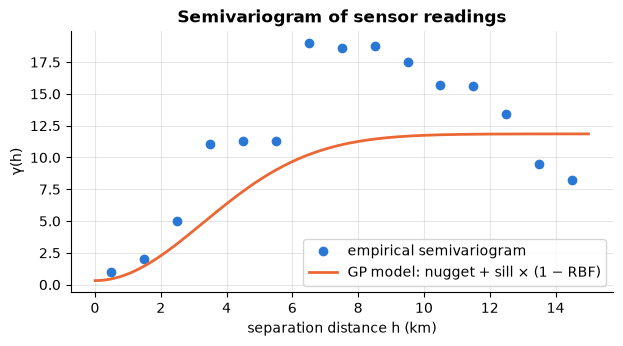

        method  LOO RMSE at sensors  RMSE vs true surface
nearest sensor                1.793                 1.755
       IDW p=1                2.837                 2.961
       IDW p=2                1.976                 2.153
       IDW p=3                1.600                 1.757
    GP kriging                0.885                 0.723
GP 95% band covers the true surface at 90.8% of grid points


In [16]:
# Empirical semivariogram from scratch vs the variogram implied by the fitted GP
D_s = cdist(S, S); iu = np.triu_indices(N_SENS, 1)
h, sq = D_s[iu], 0.5 * (sz[:, None] - sz[None, :])[iu] ** 2
edges = np.arange(0, 16, 1.0)
gamma_hat = [sq[(h >= a) & (h < b)].mean() for a, b in zip(edges[:-1], edges[1:])]
hh = np.linspace(0.01, 15, 200)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot((edges[:-1] + edges[1:]) / 2, gamma_hat, "o", color=PALETTE[0], label="empirical semivariogram")
ax.plot(hh, sn2 + sf2 * (1 - np.exp(-hh ** 2 / (2 * ell ** 2))), color=PALETTE[1], label="GP model: nugget + sill × (1 − RBF)")
ax.set(title="Semivariogram of sensor readings", xlabel="separation distance h (km)", ylabel="γ(h)")
ax.legend(); plt.show()

# Leave-one-out at the sensors + error against the known true surface on the grid
def loo(predict_fn):
    errs = []
    for i in range(N_SENS):
        m = np.arange(N_SENS) != i
        errs.append(predict_fn(S[m], sz[m], S[i:i + 1])[0] - sz[i])
    return float(np.sqrt(np.mean(np.square(errs))))

methods = {
    "nearest sensor": lambda A, z, Q: z[cdist(Q, A).argmin(1)],
    "IDW p=1": lambda A, z, Q: idw(A, z, Q, 1),
    "IDW p=2": lambda A, z, Q: idw(A, z, Q, 2),
    "IDW p=3": lambda A, z, Q: idw(A, z, Q, 3),
    "GP kriging": lambda A, z, Q: gp_predict(A, z, Q, ell, sf2, sn2)[0],
}
interp = pd.DataFrame([{"method": k, "LOO RMSE at sensors": round(loo(f), 3),
                        "RMSE vs true surface": round(float(np.sqrt(np.mean((f(S, sz, G) - truth) ** 2))), 3)}
                       for k, f in methods.items()])
print(interp.to_string(index=False))

# 95% interval coverage of the GP on the grid (against the latent truth)
lo_, hi_ = mu_ours - 1.96 * np.sqrt(var_ours), mu_ours + 1.96 * np.sqrt(var_ours)
print(f"GP 95% band covers the true surface at {100*np.mean((truth >= lo_) & (truth <= hi_)):.1f}% of grid points")

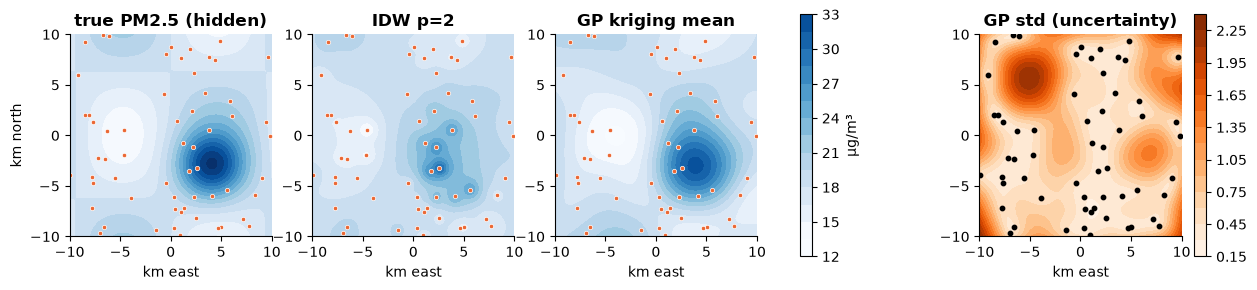

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.7))
vmin, vmax = truth.min(), truth.max()
panels = [(truth, "true PM2.5 (hidden)"), (idw(S, sz, G, 2), "IDW p=2"), (mu_ours, "GP kriging mean")]
for a, (Z, title) in zip(ax[:3], panels):
    im = a.contourf(gx, gy, Z.reshape(gx.shape), levels=15, cmap="Blues", vmin=vmin, vmax=vmax)
    a.scatter(sx, sy, s=10, color=PALETTE[1], edgecolor="white", lw=0.5)
    a.set(title=title, xlabel="km east"); a.set_aspect("equal"); a.grid(False)
ax[0].set_ylabel("km north"); plt.colorbar(im, ax=ax[:3], label="µg/m³", shrink=0.85)
im2 = ax[3].contourf(gx, gy, np.sqrt(var_ours).reshape(gx.shape), levels=15, cmap="Oranges")
ax[3].scatter(sx, sy, s=10, color="black"); ax[3].set(title="GP std (uncertainty)", xlabel="km east"); ax[3].set_aspect("equal"); ax[3].grid(False)
plt.colorbar(im2, ax=ax[3], shrink=0.85)
plt.show()

**What just happened?**
- The from-scratch GP equals scikit-learn's to numerical precision (scikit-learn's reported std adds the white-noise variance, so we added $\sigma_n^2$ before comparing). The fitted length scale is about 3.3 km. The fitted noise variance (about 0.32) is only half the true 0.64: with 60 sensors, measurement noise is hard to separate from short-range variation of the surface.
- The empirical semivariogram (dots, from pairs of sensors) starts near zero (small nugget) and rises over the first few kilometres, and the curve implied by the fitted kernel follows it there. At larger distances the dots overshoot the fitted sill and then fall again: our surface is not stationary (one big plume plus a wave pattern), and there are few sensor pairs at long distances. Kriging relies mostly on nearby sensors, so the short-range part of the fit matters most. Geostatisticians fit the variogram directly; ML practitioners maximise the marginal likelihood. Both estimate the same covariance.
- In the comparison table, GP kriging has by far the lowest error, both in leave-one-out at the sensors (0.89) and against the true surface (0.72). IDW depends strongly on the power you guess (p = 1 is worst, p = 3 is best here and only matches "copy the nearest sensor"). IDW produces "bull's-eyes" around each sensor (look at the IDW panel) because it must pass exactly through every noisy reading and knows nothing about the correlation length.
- The GP's 95% band covers the truth at about 91% of grid points, a little below 95%: the noise variance was underestimated and the fitted hyperparameters are treated as if they were known. Always check calibration like this when you can.
- Kriging's standard deviation map is low near sensors and high in the gaps, so it also tells you **where to install the next sensor**. That is the idea behind Bayesian optimisation and active learning.
- (The LOO numbers reuse hyperparameters fitted on all sensors, a mild optimism that is common in practice; refitting inside each fold is stricter.)

**Complexity:** IDW $O(nm)$ for $n$ sensors and $m$ query points. GP/kriging $O(n^3)$ to factorise $K$ once, then $O(n)$ per mean and $O(n^2)$ per variance. For many thousands of points use sparse/inducing-point GPs or local kriging neighbourhoods.

---
## 6. Spatial clustering: DBSCAN hotspots with the haversine metric

> 💬 **In plain English:** find the places where many incidents happen close together ("hotspots") without telling the algorithm how many there are, and ignore the scattered ones.

**Definition.** **DBSCAN** (Ester et al., 1996) has two parameters: a radius $\varepsilon$ and a count `min_samples`. A point is a **core point** if at least `min_samples` points (including itself) lie within $\varepsilon$; clusters are groups of core points that are within $\varepsilon$ of each other, plus the **border** points they reach. Everything else is **noise** (label −1). It finds clusters of any shape and does not need $k$.

For geographic data, use `metric="haversine"` with coordinates in radians, and convert the radius: $\varepsilon_{\text{rad}} = \varepsilon_{\text{km}}/R$. (See [clustering](../02_unsupervised/01_clustering.ipynb) for DBSCAN on ordinary features.)

                            clusters found  noise points  ARI vs truth
DBSCAN haversine (correct)             4.0         622.0         0.898
DBSCAN on raw degrees                  5.0         643.0         0.859

With eps in degrees, the east-west reach is only 161 m instead of 250 m at 50N
cluster 0: 149 points, centre at (-4.98,  4.02) km
cluster 1: 121 points, centre at ( 1.99,  1.00) km
cluster 2:  69 points, centre at ( 5.96, -5.98) km
cluster 3: 109 points, centre at (-3.02, -4.98) km


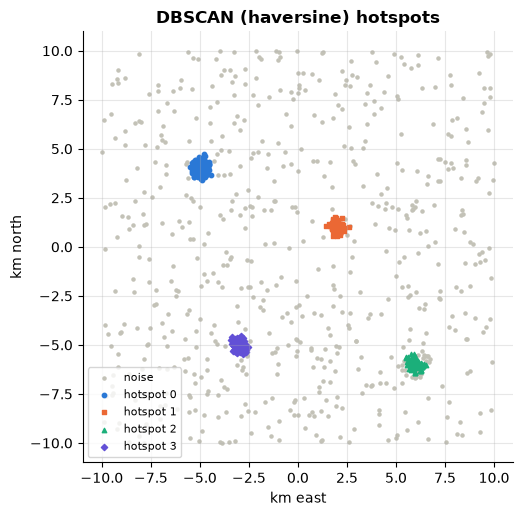

In [18]:
# Synthetic incident reports: 4 hotspots + background noise over the whole city
centres = np.array([[-5, 4], [2, 1], [6, -6], [-3, -5]])          # km
sizes, spreads = [150, 120, 90, 110], [0.25, 0.18, 0.3, 0.2]      # points and std (km)
ix, iy, truth_lab = [], [], []
for c, (n, s_) in enumerate(zip(sizes, spreads)):
    ix.append(rng.normal(centres[c, 0], s_, n)); iy.append(rng.normal(centres[c, 1], s_, n)); truth_lab += [c] * n
n_bg = 600
ix.append(rng.uniform(-10, 10, n_bg)); iy.append(rng.uniform(-10, 10, n_bg)); truth_lab += [-1] * n_bg
ix, iy, truth_lab = np.concatenate(ix), np.concatenate(iy), np.array(truth_lab)
ilat, ilon = to_latlon(ix, iy)

EPS_KM, MIN_S = 0.25, 15
db = DBSCAN(eps=EPS_KM / R_EARTH_KM, min_samples=MIN_S, metric="haversine", algorithm="ball_tree")
lab_h = db.fit_predict(np.radians(np.c_[ilat, ilon]))

# The pitfall: the same radius in "degrees" on raw lat/lon (0.25 km / 111.195 km per degree)
lab_deg = DBSCAN(eps=EPS_KM / KM_PER_DEG, min_samples=MIN_S).fit_predict(np.c_[ilat, ilon])

def summarise(lab):
    k = len(set(lab)) - (1 if -1 in lab else 0)
    return {"clusters found": k, "noise points": int((lab == -1).sum()),
            "ARI vs truth": round(adjusted_rand_score(truth_lab, lab), 3)}
print(pd.DataFrame({"DBSCAN haversine (correct)": summarise(lab_h),
                    "DBSCAN on raw degrees": summarise(lab_deg)}).T.to_string())
print(f"\nWith eps in degrees, the east-west reach is only {EPS_KM*COS0*1000:.0f} m instead of {EPS_KM*1000:.0f} m at 50N")
for c in sorted(set(lab_h) - {-1}):
    m = lab_h == c
    print(f"cluster {c}: {m.sum():3d} points, centre at ({ix[m].mean():5.2f}, {iy[m].mean():5.2f}) km")

fig, ax = plt.subplots(figsize=(6, 5.6))
ax.scatter(ix[lab_h == -1], iy[lab_h == -1], s=5, color="#c3c2b7", label="noise")
mk, hot_cols = ["o", "s", "^", "D"], [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[6]]
for c in sorted(set(lab_h) - {-1}):
    m = lab_h == c
    ax.scatter(ix[m], iy[m], s=10, marker=mk[c % 4], color=hot_cols[c % 4], label=f"hotspot {c}")
ax.set(title="DBSCAN (haversine) hotspots", xlabel="km east", ylabel="km north"); ax.set_aspect("equal")
ax.legend(fontsize=8, loc="lower left"); plt.show()

**What just happened?** With the haversine metric DBSCAN found exactly the 4 planted hotspots, labelled the scattered background as noise, and placed the cluster centres within about 50 m of the true ones (ARI 0.90). The most spread-out hotspot (cluster 2, 90 points with a 300 m spread) kept only 69 points: its sparse fringe falls below `min_samples` and becomes noise. Running DBSCAN on raw degrees with "the same" radius is subtly wrong: at 50°N a degree of longitude is only 64% as long as a degree of latitude, so the neighbourhood becomes an ellipse that is too narrow east–west, fewer points become core points, more points are called noise, and it reports 5 clusters instead of 4 (lower ARI).

**Complexity:** $O(n\log n)$ on average with a tree index (one radius query per point), $O(n^2)$ worst case. Choosing $\varepsilon$: plot each point's distance to its `min_samples`-th neighbour, sorted, and look for the "knee".

> 🎓 **Exam / interview tip:** "Why not k-means for hotspots?" k-means needs $k$, forces every point (including noise) into a cluster, assumes roughly round clusters of similar size, and uses Euclidean means that are meaningless on raw lat/lon near the poles or the antimeridian. DBSCAN/HDBSCAN handle noise, arbitrary shapes and any metric.

---
## 7. Routing and ETA on a synthetic road graph

> 💬 **In plain English:** a delivery app must predict "your food arrives in 23 minutes". It learns how fast each road is at each time of day from past GPS traces, then adds up the predicted times along the fastest route.

**Definitions.**
- A **road graph** has intersections as nodes and road segments as weighted edges. The edge weight for routing is the **travel time** $\ell_e / v_e(t)$, where $\ell_e$ is the length and $v_e(t)$ the speed at time $t$.
- An **ETA model** predicts the trip duration. A common production design is two-stage: (1) a **speed model** per edge, learned from GPS **probe** data; (2) a **shortest-path** search (Dijkstra / A*; see [classical AI route planning](../../00_AI_Fundamentals/classical_ai/11_industry_route_planning_and_scheduling.ipynb)) over predicted edge times. Real systems then add a trip-level correction model on top.

Our synthetic city: a 12 × 12 grid of intersections about 1.6 km apart with jitter, arterial roads on every fourth row and column (60 km/h free-flow) and local roads (35 km/h). True speeds drop during the morning and evening rush hours (more on arterials) and are lower near the centre, plus an unobserved per-road factor. We observe 6,000 noisy GPS speed samples.

In [19]:
GN = 12
Groad = nx.grid_2d_graph(GN, GN)
Groad = nx.convert_node_labels_to_integers(Groad, label_attribute="ij")
pos = {n: np.array([(d["ij"][0] - 5.5) * 1.6 + rng.normal(0, 0.25), (d["ij"][1] - 5.5) * 1.6 + rng.normal(0, 0.25)])
       for n, d in Groad.nodes(data=True)}
ARTERIAL = {1, 5, 9}
for u, v, d in Groad.edges(data=True):
    (iu, ju), (iv, jv) = Groad.nodes[u]["ij"], Groad.nodes[v]["ij"]
    d["arterial"] = int((iu == iv and iu in ARTERIAL) or (ju == jv and ju in ARTERIAL))
    d["length_km"] = float(np.linalg.norm(pos[u] - pos[v]))
    mx, my = (pos[u] + pos[v]) / 2
    d["mid_x"], d["mid_y"] = float(mx), float(my)
    d["hidden"] = float(rng.lognormal(0, 0.15))                      # unobserved per-road factor
EDGES = list(Groad.edges())
E = pd.DataFrame([Groad.edges[e] for e in EDGES])

def true_speed(edge_df, hour):
    """True speed (km/h) of each edge at a given hour of day."""
    hour = np.asarray(hour, float)
    free = np.where(edge_df["arterial"] == 1, 60.0, 35.0)
    rush = np.exp(-(hour - 8.0) ** 2 / 2.0) + 0.9 * np.exp(-(hour - 17.5) ** 2 / 2.0)
    rush_drop = np.where(edge_df["arterial"] == 1, 0.5, 0.25) * rush
    centre = 1 - 0.3 * np.exp(-(edge_df["mid_x"] ** 2 + edge_df["mid_y"] ** 2) / (2 * 4.0 ** 2))
    return free * (1 - rush_drop) * centre / edge_df["hidden"]

# GPS probes: random (edge, hour) samples with 10% multiplicative noise
N_PROBE = 6000
pe = rng.integers(0, len(EDGES), N_PROBE); ph = rng.uniform(0, 24, N_PROBE)
probes = E.iloc[pe][["arterial", "length_km", "mid_x", "mid_y"]].reset_index(drop=True)
probes["hour"] = ph
probes["speed"] = true_speed(E.iloc[pe].reset_index(drop=True), ph) * rng.lognormal(0, 0.10, N_PROBE)
SPEED_FEATS = ["arterial", "length_km", "mid_x", "mid_y", "hour"]
speed_model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0)
speed_model.fit(probes[SPEED_FEATS], np.log(probes["speed"]))
print(f"{len(EDGES)} road segments, {GN*GN} intersections, {N_PROBE} GPS probes; "
      f"mean observed speed {probes['speed'].mean():.1f} km/h")

def predicted_speed(hour):
    X = E[["arterial", "length_km", "mid_x", "mid_y"]].copy(); X["hour"] = hour
    return np.exp(speed_model.predict(X[SPEED_FEATS]))

for hr in (3, 8, 13, 17.5):
    tv, pv = true_speed(E, hr), predicted_speed(hr)
    print(f"hour {hr:>4}: mean true speed {tv.mean():5.1f} km/h | speed-model MAPE per edge {100*np.mean(np.abs(pv-tv)/tv):4.1f}%")

264 road segments, 144 intersections, 6000 GPS probes; mean observed speed 36.2 km/h
hour    3: mean true speed  38.5 km/h | speed-model MAPE per edge  2.6%
hour    8: mean true speed  25.4 km/h | speed-model MAPE per edge  3.6%
hour   13: mean true speed  38.5 km/h | speed-model MAPE per edge  2.7%
hour 17.5: mean true speed  26.7 km/h | speed-model MAPE per edge  3.2%


In [20]:
def dijkstra(adj, src, dst):
    """Dijkstra from scratch with a binary heap; adj[u] = list of (v, w). Returns (cost, path)."""
    dist, prev, pq, done = {src: 0.0}, {}, [(0.0, src)], set()
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)
        if u == dst:
            break
        for v, w in adj[u]:
            nd = d + w
            if nd < dist.get(v, math.inf):
                dist[v], prev[v] = nd, u
                heapq.heappush(pq, (nd, v))
    path, n = [dst], dst
    while n != src:
        n = prev[n]; path.append(n)
    return dist[dst], path[::-1]

def set_times(speeds_kmh, attr):
    for (u, v), s, L in zip(EDGES, speeds_kmh, E["length_km"]):
        Groad.edges[u, v][attr] = 60.0 * L / s                       # minutes

def path_time(path, attr):
    return sum(Groad.edges[a, b][attr] for a, b in zip(path[:-1], path[1:]))

# Check our Dijkstra against networkx on 30 random pairs at 08:00
set_times(true_speed(E, 8.0).to_numpy(), "t_true")
adj = {u: [(v, Groad.edges[u, v]["t_true"]) for v in Groad.neighbors(u)] for u in Groad.nodes}
for _ in range(30):
    a, b = rng.choice(GN * GN, 2, replace=False)
    assert math.isclose(dijkstra(adj, a, b)[0], nx.shortest_path_length(Groad, a, b, weight="t_true"))
print("from-scratch Dijkstra matches networkx on 30 random trips")

# Evaluate 300 trips at random departure hours
mean_speed = probes["speed"].mean()
rows = []
for _ in range(300):
    a, b = (int(v) for v in rng.choice(GN * GN, 2, replace=False))
    hr = float(rng.uniform(0, 24))
    set_times(true_speed(E, hr).to_numpy(), "t_true")
    set_times(predicted_speed(hr), "t_pred")
    best_true = nx.shortest_path_length(Groad, a, b, weight="t_true")            # the oracle
    p_len = nx.shortest_path(Groad, a, b, weight="length_km")                      # shortest distance
    eta_naive = 60 * sum(Groad.edges[x, y]["length_km"] for x, y in zip(p_len[:-1], p_len[1:])) / mean_speed
    p_ml = nx.shortest_path(Groad, a, b, weight="t_pred")                          # learned speeds
    rows.append({"hour": hr, "true_best": best_true,
                 "naive_eta": eta_naive, "naive_actual": path_time(p_len, "t_true"),
                 "ml_eta": path_time(p_ml, "t_pred"), "ml_actual": path_time(p_ml, "t_true")})
trips = pd.DataFrame(rows)
summary = pd.DataFrame({
    "ETA MAE (min)": [np.mean(np.abs(trips.naive_eta - trips.naive_actual)), np.mean(np.abs(trips.ml_eta - trips.ml_actual))],
    "ETA MAPE": [np.mean(np.abs(trips.naive_eta - trips.naive_actual) / trips.naive_actual),
                 np.mean(np.abs(trips.ml_eta - trips.ml_actual) / trips.ml_actual)],
    "route regret vs oracle": [np.mean(trips.naive_actual / trips.true_best - 1), np.mean(trips.ml_actual / trips.true_best - 1)],
}, index=["shortest distance + average speed", "learned speed model + fastest path"])
print(summary.assign(**{"ETA MAPE": summary["ETA MAPE"].map("{:.1%}".format),
                        "route regret vs oracle": summary["route regret vs oracle"].map("{:.1%}".format)}).round(2).to_string())

from-scratch Dijkstra matches networkx on 30 random trips


                                    ETA MAE (min) ETA MAPE route regret vs oracle
shortest distance + average speed            4.34    17.8%                  22.2%
learned speed model + fastest path           0.35     1.8%                   0.1%


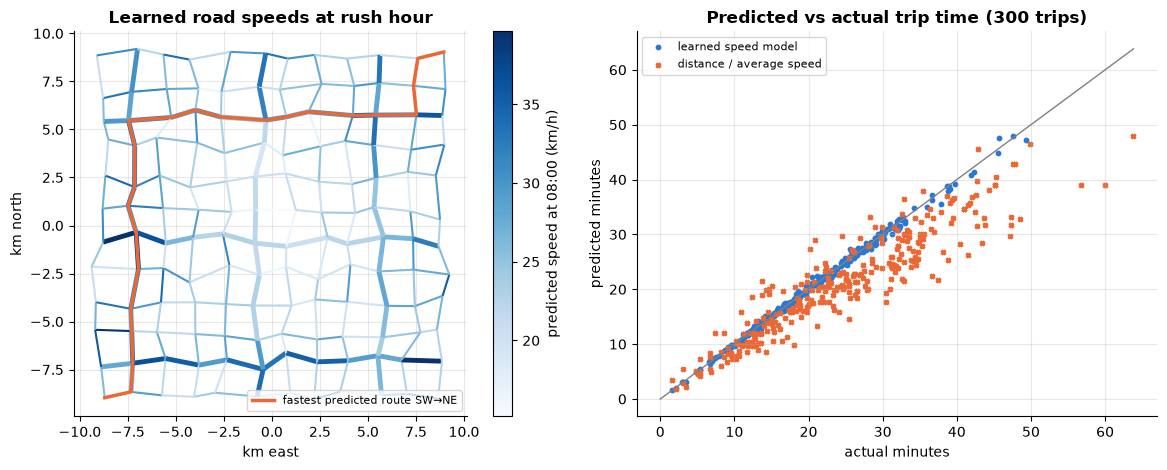

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
set_times(predicted_speed(8.0), "t_pred")
sp8 = predicted_speed(8.0)
segs = [[pos[u], pos[v]] for u, v in EDGES]
from matplotlib.collections import LineCollection
lc = LineCollection(segs, array=sp8, cmap="Blues", linewidths=np.where(E["arterial"] == 1, 3.5, 1.5))
ax[0].add_collection(lc); ax[0].autoscale(); ax[0].set_aspect("equal")
plt.colorbar(lc, ax=ax[0], label="predicted speed at 08:00 (km/h)")
a, b = 0, GN * GN - 1
p_fast = nx.shortest_path(Groad, a, b, weight="t_pred")
ax[0].plot(*np.array([pos[n] for n in p_fast]).T, color=PALETTE[1], lw=2.5, label="fastest predicted route SW→NE")
ax[0].set(title="Learned road speeds at rush hour", xlabel="km east", ylabel="km north"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].scatter(trips.ml_actual, trips.ml_eta, s=10, color=PALETTE[0], label="learned speed model")
ax[1].scatter(trips.naive_actual, trips.naive_eta, s=10, color=PALETTE[1], marker="x", label="distance / average speed")
m_ = trips[["ml_actual", "naive_actual"]].to_numpy().max()
ax[1].plot([0, m_], [0, m_], color="gray", lw=1)
ax[1].set(title="Predicted vs actual trip time (300 trips)", xlabel="actual minutes", ylabel="predicted minutes")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**What just happened?**
- Our heap-based Dijkstra returns the same costs as `networkx` (see [graphs](../../00_AI_Fundamentals/dsa/07_graphs.ipynb) for the algorithm).
- The speed model learned from GPS probes that arterials are fast at night but congested at 08:00 and 17:30, and that the centre is slow. Its per-edge error is about 3%, well below the 10% noise of a single probe: each road has about 23 probes to average over, and the midpoint coordinates let the trees recognise individual roads, so even the "hidden" per-road factor is largely learned.
- The naive ETA (shortest distance at the average speed) ignores time of day and road type: its mean error is about 4.3 minutes (18%) against about 0.35 minutes (2%) for the learned model, and the route it picks is on average 22% slower than the best possible one (**route regret**), against 0.1% for the learned fastest path. On the right, the learned ETAs hug the diagonal while the naive ones form a broad cloud.
- Simplification: we assume the hour does not change during a trip. Real systems use **time-dependent shortest paths**, where the edge time depends on the arrival time at that edge.

**Complexity:** Dijkstra with a binary heap, $O((V + E)\log V)$ per query; one batched speed prediction for all $E$ edges per time slice. Production routers precompute shortcuts (contraction hierarchies) to answer continental queries in milliseconds.

---
## 8. Polygons: point-in-polygon and spatial joins

> 💬 **In plain English:** "which district is this house in?" Draw a line from the house to the far right; if it crosses the district's border an odd number of times, the house is inside.

**Definitions.**
- **Ray casting (even–odd rule):** a point is inside a simple polygon if a ray from it crosses the boundary an odd number of times. $O(V)$ per test for a polygon with $V$ vertices. (More on polygons in [computational geometry](../../00_AI_Fundamentals/advanced_algorithms/07_computational_geometry_and_fft.ipynb).)
- A **spatial join** attaches attributes from one layer to another by a spatial predicate (`within`, `intersects`, `nearest`), the geographic version of an SQL join. In practice a spatial index first finds candidate polygons by bounding box, then the exact predicate runs.

In [22]:
def point_in_polygon(px_, py_, poly):
    """Even-odd ray casting for one point; poly is a list of (x, y) vertices (not repeated at the end)."""
    inside = False
    n = len(poly)
    for i in range(n):
        x1, y1 = poly[i]; x2, y2 = poly[(i + 1) % n]
        if (y1 > py_) != (y2 > py_):                                  # edge straddles the horizontal ray
            x_cross = x1 + (py_ - y1) * (x2 - x1) / (y2 - y1)          # where the edge meets the ray
            if px_ < x_cross:
                inside = not inside
    return inside

districts = {   # km coordinates; "Old Town" is non-convex (an L shape)
    "Old Town": [(-3, -3), (3, -3), (3, 0), (0, 0), (0, 3), (-3, 3)],
    "North": [(-11, 3), (11, 3), (11, 11), (-11, 11)],      # outer edges reach past the city limits (±10 km)
    "Riverside": [(3, -11), (11, -11), (11, 3), (3, 3)],
    "West": [(-11, -11), (-3, -11), (-3, 3), (-11, 3)],
    "South": [(-3, -11), (3, -11), (3, -3), (-3, -3)],
    "Market": [(0, 0), (3, 0), (3, 3), (0, 3)],              # fills the notch of the L
}
assign = np.full(N_HOUSES, "other", dtype=object)
t = time.perf_counter()
for name, poly in districts.items():
    inside = np.array([point_in_polygon(a, b, poly) for a, b in zip(houses["x"], houses["y"])])
    ref = MplPath(np.array(poly)).contains_points(houses[["x", "y"]].to_numpy())
    assert np.array_equal(inside, ref)                                 # (points exactly on an edge could differ)
    assign[inside] = name
print(f"ray casting agrees with matplotlib.path on all {N_HOUSES} houses x {len(districts)} districts "
      f"({time.perf_counter()-t:.2f} s)")
houses["district"] = assign
assert (houses["district"] != "other").all()                          # the districts tile the whole city
print(houses.groupby("district").agg(houses=("price_k", "size"), median_price_k=("price_k", "median"),
                                     mean_size_m2=("size_m2", "mean")).round(1).to_string())

ray casting agrees with matplotlib.path on all 3000 houses x 6 districts (0.07 s)
           houses  median_price_k  mean_size_m2
district                                       
Market        171           269.6          86.4
North         838           187.7          87.3
Old Town      452           255.8          86.6
Riverside     558           211.0          86.3
South         370           207.5          90.4
West          611           182.6          87.1


In [23]:
# OPTIONAL: the same spatial join with geopandas + shapely (skipped if they are not installed)
try:
    import geopandas as gpd
    from shapely.geometry import Polygon
    pts = gpd.GeoDataFrame(houses[["price_k"]], geometry=gpd.points_from_xy(houses["lon"], houses["lat"]),
                           crs="EPSG:4326")                                   # WGS 84 lon/lat
    polys = []
    for name, poly in districts.items():
        la_, lo_ = to_latlon(np.array(poly)[:, 0], np.array(poly)[:, 1])
        polys.append({"district": name, "geometry": Polygon(zip(lo_, la_))})  # shapely wants (x=lon, y=lat)
    gdf = gpd.GeoDataFrame(polys, crs="EPSG:4326")
    joined = gpd.sjoin(pts, gdf, how="left", predicate="within")
    print(joined.groupby("district")["price_k"].agg(["size", "median"]).round(1))
    print("areas in km^2 (projected to UTM zone 32N):",
          (gdf.to_crs("EPSG:32632").area / 1e6).round(1).tolist())
except ImportError:
    print("geopandas/shapely not installed: skipping the optional equivalent (the from-scratch version above is the lesson).")

geopandas/shapely not installed: skipping the optional equivalent (the from-scratch version above is the lesson).


**What just happened?** Ray casting assigned every house to a district and agreed with matplotlib's `Path.contains_points` (which uses the same crossing idea in C). The district table is a spatial join followed by a group-by. With geopandas installed, the optional cell does the same with `gpd.sjoin(..., predicate="within")` and computes true areas after re-projecting to UTM zone 32N (**never compute areas in degrees**).

**Complexity:** naive join $O(n \cdot P \cdot V)$ for $n$ points, $P$ polygons and $V$ vertices each; with an R-tree on polygon bounding boxes, about $O(n\log P)$ candidate lookups plus the exact tests.

---
## 9. Summary tables

> 💬 **In plain English:** which tool to reach for, at a glance.

| Task | Method | Key property | Cost |
|---|---|---|---|
| distance between two points | haversine (sphere) | ≤ 0.5% error vs the ellipsoid | $O(1)$ |
| | Vincenty / Karney (ellipsoid) | millimetre accuracy | $O(1)$, iterative |
| | Euclidean on raw degrees | **wrong**: direction- and latitude-dependent error | $O(1)$ |
| local geometry | project to UTM / local CRS, then Euclidean | < 0.1% distortion in a zone | $O(1)$ per point |
| radius / kNN queries | grid or geohash cells (+ neighbours) | simple, works in key–value stores | $O(1)$ cell lookup + candidates |
| | Ball tree (haversine), KD-tree (projected) | exact, any metric (Ball tree) | $O(\log n + k)$ |
| | H3 hexagons, S2 cells, R-trees | equal-distance neighbours / hierarchical / polygons | $O(1)$ / $O(\log n)$ |
| interpolation | IDW | exact, no uncertainty, bull's-eyes | $O(nm)$ |
| | GP / kriging | best linear unbiased, gives uncertainty | $O(n^3)$ fit |
| clustering / hotspots | DBSCAN / HDBSCAN (haversine) | finds noise, any shape, no $k$ | $O(n\log n)$ typical |

| Validation scheme | Leaks through autocorrelation? | Estimates error for... |
|---|---|---|
| random K-fold | **yes** | new points *inside* already-covered areas |
| spatial block K-fold (block ≥ range) | mostly no | new areas of similar size to the blocks |
| buffered leave-one-out | no (if buffer ≥ range) | isolated new locations |
| leave-one-region-out | no | a new district / city |

## 🔗 How this connects to modern AI

- **ETA prediction at scale.** Google Maps predicts travel times with graph neural networks over "supersegments" of the road graph (Derrow-Pinion et al., CIKM 2021); Uber's DeepETA (2022) uses a transformer to correct the routing engine's ETA, the same two-stage idea as section 7. See [GNNs](../../05_Deep_Learning/07_gnn.ipynb).
- **Hexagonal indexes as features and keys.** Uber's open-source H3 grid is used for surge pricing, demand forecasting and as categorical features (cell IDs at several resolutions) in delivery and mobility models.
- **Geospatial foundation models.** Models pretrained on satellite imagery, such as NASA/IBM's Prithvi (2023) and masked-autoencoder variants like SatMAE, are fine-tuned for flood mapping, crop classification and burn scars with few labels, the same transfer-learning idea as in [computer vision](../../06_Computer_Vision/02_image_classification.ipynb).
- **Machine-learned weather and climate.** GraphCast (Lam et al., *Science* 2023), GenCast (Price et al., *Nature* 2024) and Aurora (Bodnar et al., *Nature* 2025) are graph or transformer models on a spherical mesh; GenCast is a diffusion model that outputs a probabilistic ensemble. Getting the geometry of the sphere right (section 1) is part of their design.
- **Gaussian processes everywhere.** Kriging is the ancestor of the GP surrogates in Bayesian optimisation ([industry GP notebook](../04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb)) and of uncertainty-aware sensor placement.
- **Spatial leakage in published work.** Spatial and temporal autocorrelation have inflated reported accuracies in remote sensing and ecology papers; reviewers now ask for spatial CV, which links to [experiment design](../../24_Research_Methods/02_experiment_design_for_ml.ipynb) and [model evaluation](../06_model_evaluation/01_model_evaluation.ipynb).
- **LLMs and location.** Geocoding addresses, answering "nearest open pharmacy" questions with tool calls to a spatial database, and retrieval with geographic filters all rely on the indexes from section 2 (compare [vector databases](../../22_ML_System_Design/05_vector_databases.ipynb), which solve the same nearest-neighbour problem in high dimensions).
- Earlier repo examples: lat/lon features appear in the [house-price industry notebook](../01_supervised/15_industry_house_price_regression.ipynb); routing with A* and Dijkstra in [classical AI 11](../../00_AI_Fundamentals/classical_ai/11_industry_route_planning_and_scheduling.ipynb).

## Recap
- Latitude/longitude are **angles**: use **haversine** for distances, or **project** to a metric CRS (UTM, local equirectangular) and then use Euclidean geometry. Never treat raw degrees as a flat grid; 1° of longitude is $111.2\cos\varphi$ km.
- **Spatial indexes** (grid, geohash, H3, Ball/KD-trees, R-trees) turn $O(n)$ scans into near-constant or logarithmic lookups. Geohash prefixes nest; always search neighbouring cells too.
- **Spatial features** (distance to POIs, counts within a radius, KDE density, neighbour aggregates) encode mechanisms and transfer to new places; compute target-based ones **inside the training fold**.
- **Moran's I** measures spatial autocorrelation; the correlogram gives its range; residual Moran's I shows what the model missed.
- **Random CV leaks** under spatial autocorrelation; use **spatial block / buffered / leave-region-out CV** matched to the deployment scenario.
- **Kriging = GP regression**: best linear unbiased interpolation with uncertainty; the semivariogram and the kernel are two views of one covariance. IDW is a quick, uncertainty-free baseline.
- **DBSCAN with the haversine metric** (radius in radians = km / R) finds hotspots and noise without choosing $k$.
- **ETA** = learned edge speeds + shortest paths (+ a trip-level correction); measure both ETA error and route regret.
- **Spatial joins** = point-in-polygon (ray casting) + a spatial index; compute areas only after projecting.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy, conceptual)** At 60°N, how many km is one degree of longitude? A colleague computes distances between delivery points in Oslo (about 60°N) as `sqrt(dlat**2 + dlon**2) * 111`. By how much can they be wrong, and in which direction?

<details><summary>Show solution</summary>

$111.195\cos 60° \approx 55.6$ km. Their formula treats 1° of longitude as 111 km, so a purely east–west distance is overestimated by a factor $1/\cos 60° = 2$ (+100%); a purely north–south distance is about right. The error depends on direction, so it also changes which neighbour looks "nearest". Fix: haversine, or project to UTM zone 32N/33N first.

</details>

**2. (Easy, by hand)** Compute Moran's I for the values 2, 2, 8, 8 on four cells in a row (neighbours share an edge). Is it above or below $E[I]$?

<details><summary>Show solution</summary>

$\bar x = 5$, $z = (-3, -3, 3, 3)$, $\sum z^2 = 36$. Neighbour pairs (each counted twice): $(1,2): 9$, $(2,3): -9$, $(3,4): 9$, so $\sum w_{ij}z_iz_j = 2 \times 9 = 18$, $S_0 = 6$.
$I = \frac{4}{6}\cdot\frac{18}{36} = 0.333$, well above $E[I] = -1/3$: positive autocorrelation (low values next to low, high next to high). Check: `morans_i([2, 2, 8, 8], W_line)` gives 0.3333.

</details>

**3. (Medium, coding)** Write `destination_point(lat, lon, bearing_deg, dist_km)` that returns the point reached by travelling `dist_km` along a great circle with a given initial bearing. Test it with haversine.

<details><summary>Show solution</summary>

```python
import math
import numpy as np

R_EARTH_KM = 6371.0088

def destination_point(lat, lon, bearing_deg, dist_km):
    """Point reached from (lat, lon) after dist_km along the great circle with an initial bearing."""
    phi1, lam1, th = map(math.radians, (lat, lon, bearing_deg))
    delta = dist_km / R_EARTH_KM                      # angular distance
    phi2 = math.asin(math.sin(phi1) * math.cos(delta) + math.cos(phi1) * math.sin(delta) * math.cos(th))
    lam2 = lam1 + math.atan2(math.sin(th) * math.sin(delta) * math.cos(phi1),
                             math.cos(delta) - math.sin(phi1) * math.sin(phi2))
    return math.degrees(phi2), (math.degrees(lam2) + 540) % 360 - 180   # normalise lon to [-180, 180)
```
Tested on 500 random starts, bearings and distances up to 3,000 km: the haversine distance back to the start equals `dist_km` to within $10^{-6}$ relative error. Going 111.195 km due east from (0, 0) lands at (0, 1°).

</details>

**4. (Medium, conceptual)** Your empirical semivariogram flattens at about 3 km. You plan spatial block CV. Which block sizes are sensible, and what would happen with 200 m blocks?

<details><summary>Show solution</summary>

Blocks should be at least the autocorrelation **range** (about 3 km here), so that most test points are farther than the range from most training points; a common choice is 1–2 × the range, while keeping enough blocks for K folds. With 200 m blocks nearly every test point still has training neighbours within the range, so the estimate is almost as optimistic as random CV. Alternative: buffered CV with a 3 km buffer around each test block.

</details>

**5. (Medium, coding)** Implement spatial block K-fold **with a buffer**: remove from the training set any point closer than `buffer_km` to the test fold.

<details><summary>Show solution</summary>

```python
import numpy as np
from scipy.spatial.distance import cdist

def buffered_block_folds(xy, block_km, k, buffer_km, seed=0):
    """Spatial block K-fold with a buffer: yields (train_idx, test_idx); training points closer than
    buffer_km to ANY test point are removed from the training set."""
    xy = np.asarray(xy, float)
    b = np.floor((xy - xy.min(0)) / block_km).astype(int)
    block_id = b[:, 0] * 100000 + b[:, 1]
    blocks = np.random.default_rng(seed).permutation(np.unique(block_id))
    fold_of = {bb: i % k for i, bb in enumerate(blocks)}
    fold = np.array([fold_of[bb] for bb in block_id])
    for f in range(k):
        test = np.flatnonzero(fold == f)
        cand = np.flatnonzero(fold != f)
        dmin = cdist(xy[cand], xy[test]).min(1)            # distance to the nearest test point
        yield cand[dmin >= buffer_km], test
```
Tested on 800 random points: train and test never overlap, every training point is at least 1 km from every test point, and each point is tested exactly once.

</details>

**6. (Medium, conceptual)** Why does a model with raw lat/lon features and a random-CV R² of 0.9 often fail when the company expands to a new city, while a model with "distance to nearest station" and "population density" transfers better?

<details><summary>Show solution</summary>

Trees and kNN on lat/lon **memorise local levels**: "around (50.01, 10.02) prices are high". Random CV rewards this because test points have training neighbours (spatial autocorrelation). In a new city the coordinates are outside the training range, so the model extrapolates a constant, uninformative value. Features like distance to transport describe a **mechanism** that holds in many cities, so the learned relationship transfers. Evaluate with leave-one-city-out CV to see this before launch.

</details>

**7. (Hard, coding)** Write `gh_neighbours(gh)` returning the 8 geohash cells around a geohash of the same precision (handle longitude wrap-around; drop cells past the poles).

<details><summary>Show solution</summary>

```python
B32 = "0123456789bcdefghjkmnpqrstuvwxyz"

def gh_encode(lat, lon, precision):
    lat_r, lon_r, bits, use_lon = [-90.0, 90.0], [-180.0, 180.0], [], True
    while len(bits) < 5 * precision:
        r, v = (lon_r, lon) if use_lon else (lat_r, lat)
        mid = (r[0] + r[1]) / 2
        if v >= mid: bits.append(1); r[0] = mid
        else: bits.append(0); r[1] = mid
        use_lon = not use_lon
    return "".join(B32[int("".join(map(str, bits[i:i + 5])), 2)] for i in range(0, len(bits), 5))

def gh_bbox(gh):
    lat_r, lon_r, use_lon = [-90.0, 90.0], [-180.0, 180.0], True
    for ch in gh:
        val = B32.index(ch)
        for s in range(4, -1, -1):
            r = lon_r if use_lon else lat_r
            mid = (r[0] + r[1]) / 2
            if (val >> s) & 1: r[0] = mid
            else: r[1] = mid
            use_lon = not use_lon
    return lat_r[0], lat_r[1], lon_r[0], lon_r[1]

def gh_neighbours(gh):
    """The 8 geohash cells around gh (same precision); wraps longitude, drops cells beyond the poles."""
    a, b, c, d = gh_bbox(gh)
    lat_c, lon_c, h, w = (a + b) / 2, (c + d) / 2, b - a, d - c
    out = set()
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            if dx == dy == 0:
                continue
            la = lat_c + dy * h
            if not -90 < la < 90:
                continue
            lo = (lon_c + dx * w + 180) % 360 - 180
            out.add(gh_encode(la, lo, len(gh)))
    return sorted(out)
```
The trick is to decode the cell, step one cell height/width from its centre in each direction and re-encode. Tested: `ezs42` round trip, 8 distinct neighbours, and for 1,500 random nearby pairs the second point is always in the same cell or one of the 8 neighbours.

</details>

**8. (Hard, open-ended)** Extend section 7 so that edge times depend on the **arrival time** at each edge (a time-dependent shortest path). Which property must the travel-time function have for Dijkstra to stay correct?

<details><summary>Show solution</summary>

Run Dijkstra where the cost of edge $(u, v)$ is computed at the label time of $u$: $t_v = t_u + \tau_{uv}(t_u)$. It stays correct if the network is **FIFO** (first in, first out): leaving later never makes you arrive earlier, i.e. $t + \tau(t)$ is non-decreasing in $t$. Our smooth rush-hour speeds satisfy this for realistic edge lengths. Without FIFO, waiting at a node can help and the problem becomes much harder (NP-hard in some variants).

</details>

## Further reading
- S. Rey, D. Arribas-Bel and L. J. Wolf, *Geographic Data Science with Python* (CRC Press, 2023), free online at [geographicdata.science/book](https://geographicdata.science/book/intro.html): ch. 4 (spatial weights), ch. 6–7 (global and local spatial autocorrelation).
- N. Cressie and C. K. Wikle, *Statistics for Spatio-Temporal Data* (Wiley, 2011); N. Cressie, *Statistics for Spatial Data* (rev. ed., 1993) for kriging and variograms.
- C. E. Rasmussen and C. K. I. Williams, *Gaussian Processes for Machine Learning* (MIT Press, 2006), free at [gaussianprocess.org/gpml](http://gaussianprocess.org/gpml/), ch. 2 and 5.
- D. R. Roberts et al., "Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure", *Ecography* 40 (2017).
- M. Ester, H.-P. Kriegel, J. Sander and X. Xu, "A density-based algorithm for discovering clusters in large spatial databases with noise", KDD 1996.
- A. Derrow-Pinion et al., "ETA Prediction with Graph Neural Networks in Google Maps", CIKM 2021.
- J. P. Snyder, *Map Projections: A Working Manual* (USGS Professional Paper 1395, 1987), free from the USGS.

## Next notebook
➡️ [02 · Bioinformatics and sequence ML](02_bioinformatics_sequence_ml.ipynb): another domain where the data has structure, this time strings of DNA and protein letters, aligned with dynamic programming and decoded with HMMs.